# West Java Tourism Intelligence
### Integrasi Data Potensi Wisata, Paket Wisata JADESTA, dan Historical Weather Open-Meteo
**UTS Data Acquisition & Management — Informatika, INSTIKI**

| Metode akuisisi | Sumber | Keterangan |
|---|---|---|
| (a) Berkas dataset terbuka | CSV BPS Jawa Barat — *Kebudayaan dan Pariwisata Jawa Barat dalam Angka 2005* | 198 baris, 7 kolom |
| (b) API | Open-Meteo Historical Weather (`archive-api.open-meteo.com`) | cuaca harian 2005 |
| (c) Web scraping | JADESTA — Paket Wisata (`/paket/jenis/105`), filter Jawa Barat | hanya jika robots.txt dan ketentuan situs mengizinkan |

**Prinsip kerja:** raw data tidak diubah · setiap klaim status harus punya bukti · tidak ada data/koordinat/lisensi karangan · tidak ada bypass proteksi situs.

**Cara menjalankan:** isi `EMAIL_KAMPUS` di BAB 0, lalu jalankan sel berurutan dari atas ke bawah. Di BAB 5 ada satu sakelar manual (`TOS_SUDAH_DIBACA`) yang harus kamu isi setelah membaca ketentuan JADESTA.

## BAB 0 — Persiapan Project
Mengimpor library, menetapkan konfigurasi (User-Agent dengan email kampus, timeout, retry, jeda), membuat struktur folder, dan menyiapkan *helper* untuk request HTTP, penyimpanan raw (read-only), hash MD5, dan pencatatan provenance.

In [1]:
# Instalasi library (Colab). Abaikan jika sudah terpasang.
!pip install -q requests beautifulsoup4 lxml pandas numpy matplotlib

import glob, hashlib, json, os, re, time, warnings
from datetime import datetime, timezone
from pathlib import Path
from urllib import robotparser
from urllib.parse import urljoin, urlparse

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 80)

# =============== KONFIGURASI WAJIB DIISI ===============
EMAIL_KAMPUS = "mahasiswa@instiki.ac.id"   # <-- ganti dengan email kampusmu (syarat UTS)
assert "@" in EMAIL_KAMPUS and not EMAIL_KAMPUS.startswith("GANTI"), "Isi EMAIL_KAMPUS dengan email kampus yang sebenarnya."

# =============== PARAMETER REQUEST (syarat UTS) ===============
USER_AGENT    = f"UTS-DAM-INSTIKI/1.0 (tugas kuliah Data Acquisition; kontak: {EMAIL_KAMPUS})"
TIMEOUT       = 30      # detik
MAX_RETRY     = 3       # percobaan maksimal per request
REQUEST_DELAY = 2.5     # jeda sebelum setiap request (>= 2 detik)
assert REQUEST_DELAY >= 2 and TIMEOUT == 30 and MAX_RETRY <= 3

# =============== URL SUMBER (sesuai spesifikasi project) ===============
URL_BPS_PUBLIKASI = "https://jabar.bps.go.id/id/publication/2006/05/09/225528b03bf64b54704968de/kebudayaan-dan-pariwisata-jawa-barat-dalam-angka-2005.html"
URL_OM_ARCHIVE    = "https://archive-api.open-meteo.com/v1/archive"
URL_OM_GEOCODING  = "https://geocoding-api.open-meteo.com/v1/search"
OM_BASE           = "https://open-meteo.com"
OM_LICENSE_URLS   = [f"{OM_BASE}/en/license", f"{OM_BASE}/en/terms"]
JADESTA_BASE      = "https://jadesta.kemenpar.go.id"
JADESTA_LIST_URL  = f"{JADESTA_BASE}/paket/jenis/105"
PROVINSI_TARGET   = "Jawa Barat"
PERIODE_START, PERIODE_END = "2005-01-01", "2005-12-31"

# =============== STRUKTUR FOLDER ===============
ROOT = Path("WEST_JAVA_TOURISM_INTELLIGENCE")
DIRS = {
    "raw_main":  ROOT / "data/raw/dataset_utama",
    "raw_om":    ROOT / "data/raw/openmeteo",
    "raw_jds":   ROOT / "data/raw/jadesta",
    "interim":   ROOT / "data/interim",
    "processed": ROOT / "data/processed",
    "docs":      ROOT / "docs",
    "notebooks": ROOT / "notebooks",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# =============== STATE GLOBAL (diisi di BAB berikutnya) ===============
PROV = {}               # provenance: source_id -> dict
ROBOTS_EVIDENCE = []    # bukti pemeriksaan robots.txt
ROBOTS_RP = {}          # parser robots.txt per label (untuk cek can_fetch per URL)
LICENSE_ROWS = []       # bukti lisensi / ketentuan penggunaan
REQUEST_LOG = []        # log seluruh request web
STATUS_SCRAPING = {"dijalankan": False, "alasan": "belum dijalankan"}

print("Struktur folder dibuat di:", ROOT.resolve())

Struktur folder dibuat di: /content/WEST_JAVA_TOURISM_INTELLIGENCE


In [2]:
# ---------- HELPER: waktu, hash, penyimpanan raw, provenance ----------
def now_utc():
    # Waktu UTC ISO-8601 (tanpa mikrodetik) untuk pencatatan
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

def md5_bytes(b: bytes) -> str:
    # Hash MD5 dari isi byte (syarat provenance UTS)
    return hashlib.md5(b).hexdigest()

def md5_file(path) -> str:
    # Hash MD5 dari berkas, dibaca per potongan agar hemat memori
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def save_raw(path, content: bytes) -> Path:
    # Simpan data mentah TANPA diubah. Jika berkas sudah ada dan identik -> tidak ditulis ulang.
    # Jika ada tapi berbeda -> simpan sebagai versi baru (berkas lama tidak ditimpa).
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        if md5_file(path) == md5_bytes(content):
            return path
        path = path.with_name(f"{path.stem}_{datetime.now().strftime('%Y%m%d%H%M%S')}{path.suffix}")
    path.write_bytes(content)
    try: os.chmod(path, 0o444)          # read-only agar raw tidak sengaja berubah
    except Exception: pass
    return path

def prov_init(source_id, nama, metode, url, lisensi, catatan=""):
    # Daftarkan sumber ke provenance (URL, tanggal akses, lisensi)
    PROV[source_id] = {"source_id": source_id, "nama": nama, "metode": metode, "url": url,
                       "tanggal_akses_utc": now_utc(), "lisensi": lisensi, "status": "terdaftar",
                       "catatan": catatan, "files": []}

def prov_file(source_id, path):
    # Tambahkan berkas raw beserta MD5 dan ukuran ke sumber terkait (tanpa duplikasi)
    path = Path(path)
    rel = str(path.relative_to(ROOT)) if ROOT in path.parents else str(path)
    if any(f["path"] == rel for f in PROV[source_id]["files"]): return
    PROV[source_id]["files"].append({"path": rel, "md5": md5_file(path), "size_bytes": path.stat().st_size,
                                     "dicatat_utc": now_utc()})

def prov_save():
    # Simpan provenance ke docs/provenance.json
    out = {"project": "West Java Tourism Intelligence", "diperbarui_utc": now_utc(),
           "user_agent": USER_AGENT, "sources": list(PROV.values())}
    (DIRS["docs"] / "provenance.json").write_text(json.dumps(out, indent=2, ensure_ascii=False), encoding="utf-8")

In [3]:
# ---------- HELPER: request HTTP sopan (timeout, User-Agent, jeda, retry, log) ----------
session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "id-ID,id;q=0.9,en;q=0.8"})

def request_sopan(url, method="GET", params=None, data=None):
    # Aturan: jeda sebelum request, timeout 30 dtk, retry maks 3x HANYA untuk error jaringan/429/5xx.
    # 403 dan 4xx lain TIDAK di-retry dan tidak dilewati (tidak ada bypass).
    # Mengembalikan objek Response (apa pun statusnya) atau None jika semua percobaan gagal jaringan.
    last = None
    for attempt in range(1, MAX_RETRY + 1):
        time.sleep(REQUEST_DELAY)
        try:
            r = session.request(method, url, params=params, data=data, timeout=TIMEOUT)
        except requests.RequestException as e:
            REQUEST_LOG.append({"waktu_utc": now_utc(), "url": url, "percobaan": attempt, "status": None, "catatan": str(e)[:150]})
            last = None; continue
        REQUEST_LOG.append({"waktu_utc": now_utc(), "url": r.url, "percobaan": attempt, "status": r.status_code, "catatan": ""})
        if r.status_code == 429 or r.status_code >= 500:
            last = r; time.sleep(2 ** attempt); continue      # backoff eksponensial
        return r
    return last

def simpan_request_log():
    pd.DataFrame(REQUEST_LOG).to_csv(DIRS["docs"] / "request_log.csv", index=False, encoding="utf-8-sig")

In [4]:
# ---------- HELPER: pemeriksaan robots.txt (dengan bukti) ----------
def robots_check(base_url, target_urls, label, raw_dir):
    # Ambil robots.txt, simpan mentah, uji can_fetch untuk setiap URL target, catat bukti.
    # Keputusan: ALLOW (robots 200 & semua diizinkan) | ALLOW_NO_ROBOTS (404, tidak ada aturan)
    #            DISALLOW (ada larangan) | UNCLEAR (403/5xx/gagal -> tidak jelas -> hentikan)
    robots_url = base_url.rstrip("/") + "/robots.txt"
    r = request_sopan(robots_url)
    status = r.status_code if r is not None else None
    raw_path, md5, rp, keputusan = None, None, None, "UNCLEAR"
    if r is not None and status in (200, 404):
        domain = urlparse(base_url).netloc.replace(".", "_")
        raw_path = save_raw(Path(raw_dir) / f"robots_{domain}.txt", r.content)
        md5 = md5_file(raw_path)
    if status == 200:
        rp = robotparser.RobotFileParser(); rp.parse(r.text.splitlines())
    elif status == 404:
        keputusan = "ALLOW_NO_ROBOTS"
    rows = []
    for u in target_urls:
        can = rp.can_fetch(USER_AGENT, u) if rp is not None else None
        rows.append({"label": label, "robots_url": robots_url, "robots_http_status": status, "robots_md5": md5,
                     "target_url": u, "can_fetch": can, "crawl_delay": rp.crawl_delay(USER_AGENT) if rp else None,
                     "user_agent": USER_AGENT, "tanggal_cek_utc": now_utc(), "file_bukti": str(raw_path) if raw_path else None})
    if rp is not None:
        keputusan = "ALLOW" if all(x["can_fetch"] for x in rows) else "DISALLOW"
    for x in rows: x["keputusan"] = keputusan
    ROBOTS_RP[label] = rp
    ROBOTS_EVIDENCE.extend(rows)
    return keputusan, raw_path

def simpan_bukti_robots():
    pd.DataFrame(ROBOTS_EVIDENCE).to_csv(DIRS["docs"] / "bukti_robots.csv", index=False, encoding="utf-8-sig")

# requirements.txt untuk reproduksi
(ROOT / "requirements.txt").write_text("requests\nbeautifulsoup4\nlxml\npandas\nnumpy\nmatplotlib\n", encoding="utf-8")
print("Helper siap.")

Helper siap.


## BAB 1 — Akuisisi dan Pembacaan Dataset Utama
Berkas CSV disalin **apa adanya** ke `data/raw/dataset_utama` (read-only), lalu dibaca dengan parameter eksplisit. Cleaning hanya dilakukan pada salinan di `data/interim` (BAB 2).

Catatan parameter baca: berkas berenkoding UTF-8 dengan BOM (`utf-8-sig`), pemisah koma, dan tanda `-` pada kolom `lokasi` berarti *tidak ada informasi* sehingga dibaca sebagai `NaN` (`na_values`).

In [5]:
# Cari berkas CSV; jika tidak ada di folder kerja, minta unggah (Colab)
kandidat = (glob.glob("Pariwis*Jawa*Barat*.csv") + glob.glob("/content/Pariwis*Jawa*Barat*.csv")
            + glob.glob(str(DIRS["raw_main"] / "*.csv")))
if not kandidat:
    from google.colab import files
    kandidat = list(files.upload().keys())            # unggah 'Pariwisaata Jawa Barat.csv'
SUMBER_CSV = Path(kandidat[0])
print("Berkas CSV:", SUMBER_CSV)

# Simpan salinan mentah (tidak diubah) + catat provenance
RAW_CSV = save_raw(DIRS["raw_main"] / SUMBER_CSV.name, SUMBER_CSV.read_bytes())
assert md5_file(RAW_CSV) == md5_file(SUMBER_CSV), "Salinan raw tidak identik dengan berkas asli!"

TANGGAL_UNDUH_CSV = ""   # isi (YYYY-MM-DD) bila kamu ingat tanggal unduh asli dari BPS; kosong = tanggal registrasi di notebook
prov_init("S1_csv_bps", "CSV Potensi Wisata Jawa Barat (BPS, publikasi 2005)", "Berkas dataset terbuka", URL_BPS_PUBLIKASI,
          "BELUM DIVERIFIKASI - lihat docs/bukti_lisensi.csv (BAB 3)",
          catatan=f"Tanggal unduh asli: {TANGGAL_UNDUH_CSV or 'tidak dicatat (memakai tanggal registrasi)'}")
prov_file("S1_csv_bps", RAW_CSV); prov_save()

# Pembacaan dengan parameter eksplisit
df_raw_view = pd.read_csv(RAW_CSV, sep=",", encoding="utf-8-sig", na_values=["-", "", " "],
                          dtype={"tahun": "int64", "kabupaten_kota": "string", "lokasi": "string",
                                 "jenis_potensi": "string", "nama_objek_wisata": "string",
                                 "halaman_sumber": "int64", "tabel_sumber": "int64"})
print("\n5 baris pertama:")
display(df_raw_view.head())
print("Jumlah baris, kolom :", df_raw_view.shape)
print("Ukuran berkas       :", RAW_CSV.stat().st_size, "byte")
print("\nTipe data:"); print(df_raw_view.dtypes)

# Validasi syarat UTS: dataset terbuka minimal 100 baris
assert len(df_raw_view) >= 100, "Dataset kurang dari 100 baris"
print("\n[OK] Dataset utama >= 100 baris:", len(df_raw_view))

Saving Pariwisaata Jawa Barat.csv to Pariwisaata Jawa Barat.csv
Berkas CSV: Pariwisaata Jawa Barat.csv

5 baris pertama:


,tahun,kabupaten_kota,lokasi,jenis_potensi,nama_objek_wisata,halaman_sumber,tabel_sumber
0,2005,Kabupaten Bogor,<NA>,Budaya,Kampung Adat Tamiang,68,15
1,2005,Kabupaten Bogor,"Kec. Sukajaya, Desa Kiarapandak",Budaya,Kampung Adat Urug,68,15
2,2005,Kabupaten Bogor,"Desa Tugu Selatan, Kec. Cisarua",Alam,Telaga Warna,68,15
3,2005,Kabupaten Bogor,"Desa Tugu Selatan, Kec. Cisarua",Alam,Panorama Alam Riung Gunung,68,15
4,2005,Kabupaten Bogor,"Desa Jogjogan, Kec. Megamendung",Alam,Curug Cilember,68,15


Jumlah baris, kolom : (198, 7)
Ukuran berkas       : 15110 byte

Tipe data:
tahun                         int64
kabupaten_kota       string[python]
lokasi               string[python]
jenis_potensi        string[python]
nama_objek_wisata    string[python]
halaman_sumber                int64
tabel_sumber                  int64
dtype: object

[OK] Dataset utama >= 100 baris: 198


## BAB 2 — Identifikasi Dataset dan Estimasi Storage
Mengidentifikasi jenis data, cakupan, periode, satuan, serta memeriksa *missing value* dan duplikasi. **Tidak ada baris yang dihapus**: kandidat duplikat hanya ditandai pada salinan interim sampai dicek apakah pencatatan ganda atau dua objek berbeda.

In [6]:
df = df_raw_view.copy()      # semua pengolahan memakai salinan; raw tetap utuh

# ---- Identifikasi dataset ----
identitas = pd.DataFrame([
    ("Jenis data", "Terstruktur (tabular CSV, skema tetap 7 kolom)"),
    ("Jumlah baris x kolom", f"{df.shape[0]} x {df.shape[1]}"),
    ("Cakupan wilayah", f"{df['kabupaten_kota'].nunique()} kabupaten/kota di Provinsi Jawa Barat"),
    ("Periode data", f"{df['tahun'].min()} - {df['tahun'].max()} (hanya {df['tahun'].nunique()} tahun)"),
    ("Satuan observasi", "1 baris = 1 objek/potensi wisata pada tabel publikasi (BUKAN jumlah kunjungan)"),
    ("Satuan numerik", "Tidak ada kolom pengukuran; tahun, halaman_sumber, tabel_sumber bersifat penanda/ID"),
    ("Sumber", "BPS Provinsi Jawa Barat, Kebudayaan dan Pariwisata Jawa Barat dalam Angka 2005"),
    ("Ukuran berkas (byte)", RAW_CSV.stat().st_size),
], columns=["aspek", "nilai"])
display(identitas)

# ---- Missing value & placeholder ----
asli_str = pd.read_csv(RAW_CSV, encoding="utf-8-sig", dtype=str, keep_default_na=False)
cek_missing = pd.DataFrame({
    "missing_NaN_(setelah_na_values)": df.isna().sum(),
    "placeholder_'-'_di_berkas_asli": (asli_str == "-").sum(),
})
print("\nMissing value per kolom:"); display(cek_missing)

# ---- Duplikasi (kunci: tahun + kabupaten_kota + nama_objek_wisata) ----
KUNCI_DUP = ["tahun", "kabupaten_kota", "nama_objek_wisata"]
dup_mask = df.duplicated(KUNCI_DUP, keep=False)
print(f"\nBaris yang terlibat kandidat duplikat: {dup_mask.sum()} (catatan 'ekstra' = {df.duplicated(KUNCI_DUP).sum()})")
dup_view = df[dup_mask].sort_values(KUNCI_DUP)
display(dup_view)
# Apakah pasangan identik di SEMUA kolom (indikasi pencatatan ganda) atau berbeda (mungkin objek berbeda)?
identik = df[dup_mask].groupby(KUNCI_DUP).apply(lambda g: len(g.drop_duplicates()) == 1)
print("Identik semua kolom per kelompok (True = indikasi pencatatan ganda):"); display(identik.rename("identik_semua_kolom"))
print("Keputusan: tidak ada baris dihapus; hanya diberi flag pada data interim.")

,aspek,nilai
0,Jenis data,"Terstruktur (tabular CSV, skema tetap 7 kolom)"
1,Jumlah baris x kolom,198 x 7
2,Cakupan wilayah,23 kabupaten/kota di Provinsi Jawa Barat
3,Periode data,2005 - 2005 (hanya 1 tahun)
4,Satuan observasi,1 baris = 1 objek/potensi wisata pada tabel publikasi (BUKAN jumlah kunjungan)
5,Satuan numerik,"Tidak ada kolom pengukuran; tahun, halaman_sumber, tabel_sumber bersifat pen..."
6,Sumber,"BPS Provinsi Jawa Barat, Kebudayaan dan Pariwisata Jawa Barat dalam Angka 2005"
7,Ukuran berkas (byte),15110



Missing value per kolom:


,missing_NaN_(setelah_na_values),placeholder_'-'_di_berkas_asli
tahun,0,0
kabupaten_kota,0,0
lokasi,10,1
jenis_potensi,0,0
nama_objek_wisata,0,0
halaman_sumber,0,0
tabel_sumber,0,0



Baris yang terlibat kandidat duplikat: 6 (catatan 'ekstra' = 3)


,tahun,kabupaten_kota,lokasi,jenis_potensi,nama_objek_wisata,halaman_sumber,tabel_sumber
171,2005,Kota Bandung,Jl. BKR No. 185,Budaya,Museum Sri Baduga,77,15
173,2005,Kota Bandung,Jl. BKR No. 185,Budaya,Museum Sri Baduga,77,15
180,2005,Kota Bandung,Jl. Cihampelas,Buatan,Wisata Belanja,77,15
181,2005,Kota Bandung,Jl. Cibaduyut,Buatan,Wisata Belanja,77,15
159,2005,Kota Bogor,Jl. Ir. H. Juanda No. 9,Budaya,Museum Zoologi,76,15
162,2005,Kota Bogor,Jl.,Budaya,Museum Zoologi,76,15


Identik semua kolom per kelompok (True = indikasi pencatatan ganda):


tahun  kabupaten_kota  nama_objek_wisata
2005   Kota Bandung    Museum Sri Baduga     True
                       Wisata Belanja       False
       Kota Bogor      Museum Zoologi       False
Name: identik_semua_kolom, dtype: bool

Keputusan: tidak ada baris dihapus; hanya diberi flag pada data interim.


In [7]:
# ---- Salinan interim (cleaning ringan, TANPA menghapus baris) ----
clean = df.copy()
for c in ["kabupaten_kota", "lokasi", "jenis_potensi", "nama_objek_wisata"]:
    clean[c] = clean[c].str.strip().str.replace(r"\s+", " ", regex=True)   # rapikan spasi
clean.insert(0, "id_objek", [f"OBJ-{i:04d}" for i in range(1, len(clean) + 1)])
clean["lokasi_tidak_tersedia"] = clean["lokasi"].isna()
clean["flag_kandidat_duplikat"] = clean.duplicated(KUNCI_DUP, keep=False)
assert len(clean) == len(df_raw_view), "Cleaning tidak boleh mengubah jumlah baris"
assert clean["id_objek"].is_unique
INTERIM_CSV = DIRS["interim"] / "pariwisata_jabar_clean.csv"
clean.to_csv(INTERIM_CSV, index=False, encoding="utf-8-sig")
print("Disimpan:", INTERIM_CSV, "| baris:", len(clean))
display(clean["jenis_potensi"].value_counts().rename("jumlah").to_frame())

Disimpan: WEST_JAVA_TOURISM_INTELLIGENCE/data/interim/pariwisata_jabar_clean.csv | baris: 198


,jumlah
jenis_potensi,
Alam,108
Budaya,54
Buatan,36


In [8]:
# ---- Data dictionary ----
deskripsi = {
    "tahun": ("Tahun pencatatan objek wisata", "tahun (kalender)"),
    "kabupaten_kota": ("Kabupaten/kota lokasi objek", "-"),
    "lokasi": ("Keterangan lokasi (desa/kecamatan); '-' di sumber = tidak ada info", "-"),
    "jenis_potensi": ("Jenis potensi wisata: Alam / Budaya / Buatan", "kategori"),
    "nama_objek_wisata": ("Nama objek wisata", "-"),
    "halaman_sumber": ("Nomor halaman pada publikasi sumber", "nomor halaman"),
    "tabel_sumber": ("Nomor tabel pada publikasi sumber", "nomor tabel"),
}
dd = pd.DataFrame([{"kolom": c, "tipe_data": str(df[c].dtype), "deskripsi": deskripsi[c][0], "satuan": deskripsi[c][1],
                    "contoh": str(df[c].dropna().iloc[0]), "jumlah_missing": int(df[c].isna().sum()),
                    "jumlah_unik": int(df[c].nunique())} for c in df.columns])
dd.to_csv(DIRS["docs"] / "data_dictionary.csv", index=False, encoding="utf-8-sig")
display(dd)

,kolom,tipe_data,deskripsi,satuan,contoh,jumlah_missing,jumlah_unik
0,tahun,int64,Tahun pencatatan objek wisata,tahun (kalender),2005,0,1
1,kabupaten_kota,string,Kabupaten/kota lokasi objek,-,Kabupaten Bogor,0,23
2,lokasi,string,Keterangan lokasi (desa/kecamatan); '-' di sumber = tidak ada info,-,"Kec. Sukajaya, Desa Kiarapandak",10,154
3,jenis_potensi,string,Jenis potensi wisata: Alam / Budaya / Buatan,kategori,Budaya,0,3
4,nama_objek_wisata,string,Nama objek wisata,-,Kampung Adat Tamiang,0,194
5,halaman_sumber,int64,Nomor halaman pada publikasi sumber,nomor halaman,68,0,11
6,tabel_sumber,int64,Nomor tabel pada publikasi sumber,nomor tabel,15,0,1


In [9]:
# ---- Estimasi storage 1 tahun: ukuran_file x 12 x 1.30 ----
ukuran_byte = RAW_CSV.stat().st_size
FAKTOR_CADANGAN = 1.30                                  # cadangan 30%
tahunan_tanpa_cadangan = ukuran_byte * 12
tahunan_total = ukuran_byte * 12 * FAKTOR_CADANGAN
storage = pd.DataFrame([
    ("ukuran_file_byte", ukuran_byte),
    ("ukuran_file_KB", round(ukuran_byte / 1024, 2)),
    ("bulan", 12),
    ("estimasi_12_bulan_byte", tahunan_tanpa_cadangan),
    ("cadangan_30_persen_byte", round(tahunan_tanpa_cadangan * 0.30, 1)),
    ("total_estimasi_1_tahun_byte", round(tahunan_total, 1)),
    ("total_estimasi_1_tahun_KB", round(tahunan_total / 1024, 2)),
    ("rumus", "ukuran_file x 12 x 1.30"),
    ("asumsi_1", "Satu salinan dataset (setara satu snapshot) disimpan tiap bulan selama 12 bulan"),
    ("asumsi_2", "Ukuran per snapshot tetap sama dengan berkas saat ini (dataset historis 2005, tidak bertambah)"),
    ("asumsi_3", "Cadangan 30% untuk versi interim/processed, metadata, dan pertumbuhan data"),
    ("asumsi_4", "Belum termasuk raw API/HTML (dihitung terpisah di BAB 7)"),
], columns=["komponen", "nilai"])
storage.to_csv(DIRS["docs"] / "storage_estimation.csv", index=False, encoding="utf-8-sig")
display(storage)

,komponen,nilai
0,ukuran_file_byte,15110
1,ukuran_file_KB,14.76
2,bulan,12
3,estimasi_12_bulan_byte,181320
4,cadangan_30_persen_byte,54396.0
5,total_estimasi_1_tahun_byte,235716.0
6,total_estimasi_1_tahun_KB,230.19
7,rumus,ukuran_file x 12 x 1.30
8,asumsi_1,Satu salinan dataset (setara satu snapshot) disimpan tiap bulan selama 12 bulan
9,asumsi_2,Ukuran per snapshot tetap sama dengan berkas saat ini (dataset historis 2005...


## BAB 3 — Lisensi, PII, dan Data Ethics Checklist
Bukti ketentuan penggunaan dikumpulkan dari halaman sumber (setelah memeriksa `robots.txt` domain terkait). **Notebook tidak menyatakan lisensi yang tidak ditemukan buktinya**: bila tidak terbaca otomatis, statusnya *Perlu verifikasi manual*. Isi variabel `CATATAN_MANUAL_*` setelah kamu membaca ketentuan di situs.

In [10]:
# ---- Bukti lisensi / ketentuan (BPS & Open-Meteo) ----
CATATAN_MANUAL_BPS = ""    # contoh: "Hak cipta BPS; boleh dipakai untuk non-komersial dengan menyebut sumber (dibaca dari <URL>, tanggal ...)"
CATATAN_MANUAL_OM  = ""    # opsional

def ambil_bukti_lisensi(label, source_id, base_url, urls, pola, raw_dir, nama_file):
    # robots check -> ambil halaman -> simpan raw -> cari pola lisensi -> catat baris bukti
    keputusan, _ = robots_check(base_url, urls, label, raw_dir)
    hasil = []
    for i, u in enumerate(urls, 1):
        row = {"sumber": label, "url": u, "tanggal_akses_utc": now_utc(), "keputusan_robots": keputusan,
               "http_status": None, "pola_ditemukan": False, "kutipan_konteks": "", "file_bukti": None, "md5_bukti": None}
        if keputusan.startswith("ALLOW"):
            r = request_sopan(u)
            row["http_status"] = r.status_code if r is not None else None
            if r is not None and r.status_code == 200:
                p = save_raw(Path(raw_dir) / f"{nama_file}_{i}.html", r.content)
                prov_file(source_id, p)
                teks = BeautifulSoup(r.text, "lxml").get_text(" ", strip=True)
                m = re.search(pola, teks, re.I)
                row.update({"pola_ditemukan": bool(m), "file_bukti": str(p), "md5_bukti": md5_file(p),
                            "kutipan_konteks": teks[max(0, m.start() - 80): m.end() + 120] if m else ""})
        hasil.append(row)
    return hasil

# Open-Meteo: cari pernyataan CC BY 4.0
prov_init("S2_openmeteo_api", "Open-Meteo Historical Weather API", "API", URL_OM_ARCHIVE,
          "CC BY 4.0 (sesuai spesifikasi project; bukti halaman lisensi di docs/bukti_lisensi.csv)",
          catatan="Atribusi: Weather data by Open-Meteo.com")
rows_om = ambil_bukti_lisensi("Open-Meteo", "S2_openmeteo_api", OM_BASE, OM_LICENSE_URLS,
                              r"CC BY 4\.0|Creative Commons Attribution 4\.0", DIRS["raw_om"], "openmeteo_lisensi")
# BPS: cari kata kunci hak cipta / ketentuan pada halaman publikasi
rows_bps = ambil_bukti_lisensi("BPS Jawa Barat (halaman publikasi)", "S1_csv_bps",
                               "https://jabar.bps.go.id", [URL_BPS_PUBLIKASI],
                               r"lisensi|license|hak cipta|copyright|ketentuan|syarat", DIRS["raw_main"], "bps_halaman_publikasi")

def status_verifikasi(row, catatan_manual, pola_ok_teks):
    if catatan_manual: return "Terdokumentasi manual (lihat catatan)"
    if row["pola_ditemukan"]: return pola_ok_teks
    if row["http_status"] == 200: return "Perlu verifikasi manual - halaman terbaca tapi pernyataan lisensi tidak ditemukan"
    return "Perlu verifikasi manual - halaman tidak dapat diambil (robots/status HTTP)"

for r_ in rows_om:  r_["status_verifikasi"] = status_verifikasi(r_, CATATAN_MANUAL_OM, "Terverifikasi: pola CC BY 4.0 ditemukan di halaman")
for r_ in rows_bps: r_["status_verifikasi"] = status_verifikasi(r_, CATATAN_MANUAL_BPS, "Teks terkait lisensi/hak cipta ditemukan - BACA MANUAL untuk simpulan")
LICENSE_ROWS = rows_om + rows_bps
if CATATAN_MANUAL_BPS: LICENSE_ROWS.append({"sumber": "BPS (catatan manual)", "url": URL_BPS_PUBLIKASI, "tanggal_akses_utc": now_utc(),
                                            "status_verifikasi": "Terdokumentasi manual", "kutipan_konteks": CATATAN_MANUAL_BPS})
df_lisensi = pd.DataFrame(LICENSE_ROWS)
df_lisensi.to_csv(DIRS["docs"] / "bukti_lisensi.csv", index=False, encoding="utf-8-sig")
simpan_bukti_robots(); prov_save(); simpan_request_log()
display(df_lisensi[["sumber", "url", "http_status", "pola_ditemukan", "status_verifikasi"]])

,sumber,url,http_status,pola_ditemukan,status_verifikasi
0,Open-Meteo,https://open-meteo.com/en/license,200.0,False,Perlu verifikasi manual - halaman terbaca tapi pernyataan lisensi tidak dite...
1,Open-Meteo,https://open-meteo.com/en/terms,200.0,False,Perlu verifikasi manual - halaman terbaca tapi pernyataan lisensi tidak dite...
2,BPS Jawa Barat (halaman publikasi),https://jabar.bps.go.id/id/publication/2006/05/09/225528b03bf64b54704968de/k...,NaN,False,Perlu verifikasi manual - halaman tidak dapat diambil (robots/status HTTP)


In [11]:
# ---- Pemindaian PII dan quasi-identifier ----
POLA_PII = {"email": r"[\w.\-+]+@[\w\-]+\.[\w.\-]+", "telepon_id": r"(?:\+62|\b62|\b0)8\d{7,12}\b", "nik_16_digit": r"\b\d{16}\b"}
klasifikasi = {
    "tahun": ("Bukan PII", "Atribut waktu"),
    "kabupaten_kota": ("Quasi-identifier lemah (geografis)", "Wilayah luas; objeknya tempat wisata, bukan individu"),
    "lokasi": ("Quasi-identifier lemah (geografis)", "Desa/kecamatan lokasi objek publik, bukan alamat rumah individu"),
    "jenis_potensi": ("Bukan PII", "Kategori objek"),
    "nama_objek_wisata": ("Bukan PII (nama tempat)", "Sebagian nama bisa memuat nama tokoh/situs sejarah; tetap informasi publik tentang tempat"),
    "halaman_sumber": ("Bukan PII", "Penanda sumber"), "tabel_sumber": ("Bukan PII", "Penanda sumber"),
}
pii_rows = []
for c in df.columns:
    teks = df[c].astype("string").fillna("")
    hits = {k: int(teks.str.contains(p, regex=True).sum()) for k, p in POLA_PII.items()}
    kls, alasan = klasifikasi[c]
    pii_rows.append({"sumber": "dataset_utama", "kolom": c, "tipe": str(df[c].dtype), **{f"hit_{k}": v for k, v in hits.items()},
                     "klasifikasi": kls, "alasan": alasan, "tindakan": "Dipertahankan" if sum(hits.values()) == 0 else "PERIKSA"})
df_pii = pd.DataFrame(pii_rows)
df_pii.to_csv(DIRS["docs"] / "pii_scan.csv", index=False, encoding="utf-8-sig")
display(df_pii)
assert df_pii[[c for c in df_pii.columns if c.startswith("hit_")]].sum().sum() == 0, "Ditemukan pola PII pada dataset utama - periksa!"
print("[OK] Tidak ada pola email/telepon/NIK pada dataset utama.")

,sumber,kolom,tipe,hit_email,hit_telepon_id,hit_nik_16_digit,klasifikasi,alasan,tindakan
0,dataset_utama,tahun,int64,0,0,0,Bukan PII,Atribut waktu,Dipertahankan
1,dataset_utama,kabupaten_kota,string,0,0,0,Quasi-identifier lemah (geografis),"Wilayah luas; objeknya tempat wisata, bukan individu",Dipertahankan
2,dataset_utama,lokasi,string,0,0,0,Quasi-identifier lemah (geografis),"Desa/kecamatan lokasi objek publik, bukan alamat rumah individu",Dipertahankan
3,dataset_utama,jenis_potensi,string,0,0,0,Bukan PII,Kategori objek,Dipertahankan
4,dataset_utama,nama_objek_wisata,string,0,0,0,Bukan PII (nama tempat),Sebagian nama bisa memuat nama tokoh/situs sejarah; tetap informasi publik t...,Dipertahankan
5,dataset_utama,halaman_sumber,int64,0,0,0,Bukan PII,Penanda sumber,Dipertahankan
6,dataset_utama,tabel_sumber,int64,0,0,0,Bukan PII,Penanda sumber,Dipertahankan


[OK] Tidak ada pola email/telepon/NIK pada dataset utama.


In [12]:
# ---- README (berisi tujuan, bias/keterbatasan, keamanan & retensi: bukti butir checklist 7-9) ----
README = f'''# West Java Tourism Intelligence (UTS Data Acquisition & Management)

Integrasi inventaris potensi wisata Jawa Barat (BPS, 2005), cuaca historis Open-Meteo (2005), dan paket wisata JADESTA.

## Struktur
`data/raw` (mentah, read-only) · `data/interim` · `data/processed` · `docs` (provenance, checklist, bukti) · `notebooks`

## Tujuan penggunaan data
Tugas akademik UTS (non-komersial): mempraktikkan akuisisi (berkas, API, scraping), provenance, etika data, dan integrasi.
Hasil tidak dimaksudkan sebagai dasar kebijakan atau klaim jumlah kunjungan wisatawan.

## Keterbatasan dan potensi bias
- CSV utama hanya tahun 2005: inventaris objek, bukan kunjungan; objek yang tidak tercatat di publikasi tidak ada.
- Koordinat objek tidak tersedia dari sumber yang diizinkan; cuaca diambil pada titik acuan kabupaten/kota (bukan lokasi objek) sehingga mengabaikan variasi mikroiklim/ketinggian.
- Open-Meteo historis berbasis reanalisis (grid), bukan stasiun di lokasi objek.
- JADESTA berisi paket desa wisata yang terdaftar saat scraping (bukan 2005), tidak mewakili seluruh pariwisata; sampel scraping dibatasi.
- Perubahan batas wilayah sejak 2005 (mis. pemekaran) dapat menggeser pemetaan kabupaten/kota.
- Periode berbeda antar sumber: tidak boleh ditafsirkan sebagai kondisi yang sama.

## Keamanan, penyimpanan, penghapusan
- Tidak ada API key/token; Open-Meteo dipakai tanpa key (non-komersial). Tidak ada kredensial pada notebook.
- Raw disimpan read-only; hash MD5 pada docs/provenance.json; verifikasi ulang di BAB 7.
- Data kontak pribadi (telepon/email desa wisata) tidak dikumpulkan.
- Retensi: data dipakai untuk penilaian UTS; setelah semester selesai salinan lokal/Colab dihapus kecuali diminta dosen.

## Atribusi
Weather data by Open-Meteo.com (lisensi CC BY 4.0 sesuai ketentuan yang dirujuk; lihat docs/bukti_lisensi.csv).
Data potensi wisata: BPS Provinsi Jawa Barat. Data paket wisata: JADESTA, Kementerian Pariwisata RI.
'''
(ROOT / "README.md").write_text(README, encoding="utf-8")
print("README.md ditulis.")

README.md ditulis.


In [13]:
# ---- Data Ethics Checklist (9 butir): status HANYA 'Selesai' jika ada bukti ----
def ada(p):
    p = Path(p); return p.exists() and p.stat().st_size > 0

def build_checklist():
    docs = DIRS["docs"]
    lic = pd.read_csv(docs / "bukti_lisensi.csv") if ada(docs / "bukti_lisensi.csv") else pd.DataFrame()
    def lic_status(prefix):
        if lic.empty or "sumber" not in lic: return "Belum selesai"
        s = lic[lic["sumber"].astype(str).str.startswith(prefix)]["status_verifikasi"].astype(str)
        if s.str.startswith(("Terverifikasi", "Terdokumentasi")).any(): return "Selesai"
        return "Perlu verifikasi manual" if len(s) else "Belum selesai"
    # Ringkas status JADESTA: robots + ToS
    robots_j = [r for r in ROBOTS_EVIDENCE if "JADESTA" in r["label"]]
    jds_robots_ok = bool(robots_j) and robots_j[0]["keputusan"] in ("ALLOW", "ALLOW_NO_ROBOTS")
    tos_ok = bool(globals().get("TOS_SUDAH_DIBACA", False)) and bool(str(globals().get("TOS_CATATAN", "")).strip())
    if not robots_j: st_jds = "Belum selesai"
    elif not jds_robots_ok: st_jds = "Selesai (scraping dihentikan: robots.txt melarang/tidak jelas - terdokumentasi)"
    elif tos_ok: st_jds = "Selesai"
    else: st_jds = "Perlu verifikasi manual (ToS belum dikonfirmasi)"
    kolom_scrape_ok = True
    if "df_jds" in globals() and len(df_jds):
        kolom_scrape_ok = set(df_jds.columns) <= set(KOLOM_SCRAPING)
    prov_ok = ada(docs / "provenance.json") and all(s["files"] for s in PROV.values() if s["status"] != "dibatalkan")
    raw_files = [f for f in glob.glob(str(ROOT / "data/raw/**/*.*"), recursive=True)]
    raw_ro = bool(raw_files) and all((os.stat(f).st_mode & 0o222) == 0 for f in raw_files)   # tidak ada bit tulis -> read-only
    readme = (ROOT / "README.md").read_text(encoding="utf-8") if ada(ROOT / "README.md") else ""
    rows = [
        (1, "Sumber & provenance (URL, tanggal akses, lisensi, MD5)", "Selesai" if prov_ok else "Belum selesai",
         "docs/provenance.json", "Setiap sumber punya berkas raw + MD5; diverifikasi ulang di BAB 7"),
        (2, "Lisensi/ketentuan dataset BPS diperiksa", lic_status("BPS"),
         "docs/bukti_lisensi.csv; raw/dataset_utama/bps_halaman_publikasi_1.html", "Jika 'Perlu verifikasi manual', baca halaman BPS lalu isi CATATAN_MANUAL_BPS"),
        (3, "Ketentuan Open-Meteo (lisensi CC BY 4.0 & atribusi)", lic_status("Open-Meteo"),
         "docs/bukti_lisensi.csv; raw/openmeteo/openmeteo_lisensi_*.html", "Atribusi: Weather data by Open-Meteo.com"),
        (4, "Ketentuan JADESTA (robots.txt + Terms of Service)", st_jds,
         "docs/bukti_robots.csv; raw/jadesta/robots_*.txt; docs/bukti_lisensi.csv", "Scraping hanya jika robots mengizinkan DAN ToS sudah dikonfirmasi"),
        (5, "Identifikasi PII & quasi-identifier", "Selesai" if ada(DIRS["docs"] / "pii_scan.csv") else "Belum selesai",
         "docs/pii_scan.csv", "Tidak ada pola email/telepon/NIK; lokasi = quasi-identifier lemah"),
        (6, "Data minimization (tanpa kontak pribadi, kolom seperlunya)", "Selesai" if kolom_scrape_ok else "Belum selesai",
         "KOLOM_SCRAPING pada BAB 5; docs/scraping_quality_report.csv", "Telepon/email kontak desa tidak diambil"),
        (7, "Potensi bias & keterbatasan data didokumentasikan", "Selesai" if "Keterbatasan dan potensi bias" in readme else "Belum selesai",
         "README.md (bagian Keterbatasan)", "Periode berbeda, koordinat tingkat kabupaten/kota, reanalisis grid"),
        (8, "Tujuan penggunaan data dinyatakan", "Selesai" if "Tujuan penggunaan data" in readme else "Belum selesai",
         "README.md (bagian Tujuan)", "Akademik, non-komersial"),
        (9, "Keamanan, penyimpanan, dan penghapusan data", "Selesai" if ("Keamanan, penyimpanan, penghapusan" in readme and raw_ro) else "Belum selesai",
         "README.md; raw read-only; tanpa API key", "Retensi: dihapus setelah semester kecuali diminta dosen"),
    ]
    return pd.DataFrame(rows, columns=["no", "aspek_etika", "status", "bukti", "catatan"])

KOLOM_SCRAPING = ["nama_paket", "nama_desa_wisata", "kabupaten_kota", "provinsi", "harga", "deskripsi", "fasilitas",
                  "url_detail", "url_sumber", "tanggal_scraping"]
TOS_SUDAH_DIBACA, TOS_CATATAN = False, ""      # diisi ulang di BAB 5
checklist = build_checklist()
checklist.to_csv(DIRS["docs"] / "data_ethics_checklist.csv", index=False, encoding="utf-8-sig")
display(checklist)

,no,aspek_etika,status,bukti,catatan
0,1,"Sumber & provenance (URL, tanggal akses, lisensi, MD5)",Selesai,docs/provenance.json,Setiap sumber punya berkas raw + MD5; diverifikasi ulang di BAB 7
1,2,Lisensi/ketentuan dataset BPS diperiksa,Perlu verifikasi manual,docs/bukti_lisensi.csv; raw/dataset_utama/bps_halaman_publikasi_1.html,"Jika 'Perlu verifikasi manual', baca halaman BPS lalu isi CATATAN_MANUAL_BPS"
2,3,Ketentuan Open-Meteo (lisensi CC BY 4.0 & atribusi),Perlu verifikasi manual,docs/bukti_lisensi.csv; raw/openmeteo/openmeteo_lisensi_*.html,Atribusi: Weather data by Open-Meteo.com
3,4,Ketentuan JADESTA (robots.txt + Terms of Service),Belum selesai,docs/bukti_robots.csv; raw/jadesta/robots_*.txt; docs/bukti_lisensi.csv,Scraping hanya jika robots mengizinkan DAN ToS sudah dikonfirmasi
4,5,Identifikasi PII & quasi-identifier,Selesai,docs/pii_scan.csv,Tidak ada pola email/telepon/NIK; lokasi = quasi-identifier lemah
5,6,"Data minimization (tanpa kontak pribadi, kolom seperlunya)",Selesai,KOLOM_SCRAPING pada BAB 5; docs/scraping_quality_report.csv,Telepon/email kontak desa tidak diambil
6,7,Potensi bias & keterbatasan data didokumentasikan,Selesai,README.md (bagian Keterbatasan),"Periode berbeda, koordinat tingkat kabupaten/kota, reanalisis grid"
7,8,Tujuan penggunaan data dinyatakan,Selesai,README.md (bagian Tujuan),"Akademik, non-komersial"
8,9,"Keamanan, penyimpanan, dan penghapusan data",Selesai,README.md; raw read-only; tanpa API key,Retensi: dihapus setelah semester kecuali diminta dosen


## BAB 4 — Akuisisi API Open-Meteo (Historical Weather 2005)

**Koordinat — keputusan metodologis.** CSV tidak memuat koordinat, dan sumber yang lazim (Google Maps) dilarang UTS. Koordinat objek wisata karena itu **dicatat `missing`**. Sebagai gantinya, titik acuan tiap **kabupaten/kota** dicari lewat *Open-Meteo Geocoding API* menggunakan nama pusat administrasinya sebagai kata kunci pencarian, lalu **diverifikasi** otomatis (negara = ID, provinsi = Jawa Barat/West Java, koordinat di dalam kotak batas Jawa Barat, serta kecocokan nama admin2 bila tersedia). Titik yang gagal verifikasi dicatat `missing` — tidak ada koordinat tebakan. Kamu bisa mengisi `KOORDINAT_MANUAL` dari sumber yang kamu verifikasi sendiri.

Cuaca (suhu, hujan, kelembapan, angin) bersifat regional sehingga titik acuan kabupaten/kota masuk akal, tetapi **bukan** cuaca persis di objek.

In [14]:
daftar_wilayah = sorted(clean["kabupaten_kota"].unique())
print(len(daftar_wilayah), "kabupaten/kota:", daftar_wilayah)

# Kata kunci pencarian = nama pusat administrasi kabupaten (petunjuk pencarian, BUKAN koordinat).
# Untuk 'Kota X' dipakai 'X'. Hasil tetap harus lolos verifikasi di bawah.
KATA_KUNCI = {
    "Kabupaten Bandung": ["Soreang"], "Kabupaten Bogor": ["Cibinong"], "Kabupaten Ciamis": ["Ciamis"],
    "Kabupaten Cianjur": ["Cianjur"], "Kabupaten Cirebon": ["Sumber"], "Kabupaten Garut": ["Garut"],
    "Kabupaten Indramayu": ["Indramayu"], "Kabupaten Karawang": ["Karawang"], "Kabupaten Kuningan": ["Kuningan"],
    "Kabupaten Majalengka": ["Majalengka"], "Kabupaten Purwakarta": ["Purwakarta"], "Kabupaten Subang": ["Subang"],
    "Kabupaten Sukabumi": ["Pelabuhanratu", "Palabuhanratu"], "Kabupaten Sumedang": ["Sumedang"],
    "Kabupaten Tasikmalaya": ["Singaparna"],
}
KOORDINAT_MANUAL = {}   # contoh: {"Kabupaten Cirebon": (-6.77, 108.48, "sumber verifikasi: ...")}
BBOX_JABAR = (-7.85, -5.85, 106.3, 108.9)    # (lat_min, lat_max, lon_min, lon_max) kotak kasar Jawa Barat untuk verifikasi
ADMIN1_OK = {"west java", "jawa barat"}

def nama_dasar(w): return re.sub(r"^(kabupaten|kota)\s+", "", w, flags=re.I).strip()
def tipe_wil(s):
    s = (s or "").lower()
    if re.search(r"\bkota\b|\bcity\b", s): return "kota"
    if re.search(r"kabupaten|\bkab\b|regency", s): return "kabupaten"
    return None

def pilih_kandidat(wil, results):
    # Verifikasi & ranking kandidat dari respons geocoding
    tipe_harap = "kota" if wil.lower().startswith("kota") else "kabupaten"
    dasar = nama_dasar(wil).lower()
    ok = []
    for c in results or []:
        if c.get("country_code") != "ID" or str(c.get("admin1", "")).lower() not in ADMIN1_OK: continue
        lat, lon = c.get("latitude"), c.get("longitude")
        if lat is None or not (BBOX_JABAR[0] <= lat <= BBOX_JABAR[1] and BBOX_JABAR[2] <= lon <= BBOX_JABAR[3]): continue
        teks_admin = " ".join(str(c.get(k, "")) for k in ("admin2", "admin3")).lower()
        tipe_admin = tipe_wil(str(c.get("admin2", "")))
        cocok_nama = dasar in teks_admin
        cocok_tipe = tipe_admin in (None, tipe_harap)
        level = "A_admin2_cocok" if (cocok_nama and cocok_tipe) else "B_hanya_bbox_jabar"
        ok.append((level, c.get("feature_code") == "PPLA2", c.get("population") or 0, c))
    if not ok: return None, None
    ok.sort(key=lambda x: (x[0] != "A_admin2_cocok", not x[1], -x[2]))
    return ok[0][0], ok[0][3]

def geocode_wilayah(wil):
    # Coba kata kunci berurutan; simpan JSON mentah tiap query
    kunci = KATA_KUNCI.get(wil, [nama_dasar(wil)])
    for q in kunci:
        r = request_sopan(URL_OM_GEOCODING, params={"name": q, "count": 10, "language": "en", "format": "json"})
        if r is None or r.status_code != 200: continue
        p = save_raw(DIRS["raw_om"] / f"geocoding_{re.sub(r'[^a-z0-9]+', '_', wil.lower())}__{q.lower()}.json", r.content)
        prov_file("S2_openmeteo_api", p)
        level, cand = pilih_kandidat(wil, r.json().get("results"))
        if cand: return q, level, cand
    return None, None, None

koordinat = []
for w in daftar_wilayah:
    if w in KOORDINAT_MANUAL:
        lat, lon, src = KOORDINAT_MANUAL[w]
        koordinat.append({"kabupaten_kota": w, "query": "manual", "nama_hasil": None, "admin1": None, "admin2": None, "latitude": lat,
                          "longitude": lon, "feature_code": None, "level_verifikasi": "Manual", "status": "ok", "sumber": src}); continue
    q, level, c = geocode_wilayah(w)
    if c:
        koordinat.append({"kabupaten_kota": w, "query": q, "nama_hasil": c.get("name"), "admin1": c.get("admin1"), "admin2": c.get("admin2"),
                          "latitude": c["latitude"], "longitude": c["longitude"], "feature_code": c.get("feature_code"),
                          "level_verifikasi": level, "status": "ok", "sumber": "Open-Meteo Geocoding API"})
    else:
        koordinat.append({"kabupaten_kota": w, "query": ", ".join(KATA_KUNCI.get(w, [nama_dasar(w)])), "nama_hasil": None, "admin1": None,
                          "admin2": None, "latitude": np.nan, "longitude": np.nan, "feature_code": None,
                          "level_verifikasi": None, "status": "missing", "sumber": "tidak terverifikasi"})
df_koord = pd.DataFrame(koordinat)
df_koord.to_csv(DIRS["interim"] / "koordinat_wilayah.csv", index=False, encoding="utf-8-sig")
prov_save()
display(df_koord)
print("Koordinat ok:", (df_koord.status == "ok").sum(), "| missing:", (df_koord.status == "missing").sum(),
      "| level B (bbox saja, cek manual):", (df_koord.level_verifikasi == "B_hanya_bbox_jabar").sum())

23 kabupaten/kota: ['Kabupaten Bandung', 'Kabupaten Bogor', 'Kabupaten Ciamis', 'Kabupaten Cianjur', 'Kabupaten Cirebon', 'Kabupaten Garut', 'Kabupaten Indramayu', 'Kabupaten Karawang', 'Kabupaten Kuningan', 'Kabupaten Majalengka', 'Kabupaten Purwakarta', 'Kabupaten Subang', 'Kabupaten Sukabumi', 'Kabupaten Sumedang', 'Kabupaten Tasikmalaya', 'Kota Bandung', 'Kota Banjar', 'Kota Bogor', 'Kota Cimahi', 'Kota Cirebon', 'Kota Depok', 'Kota Sukabumi', 'Kota Tasikmalaya']


,kabupaten_kota,query,nama_hasil,admin1,admin2,latitude,longitude,feature_code,level_verifikasi,status,sumber
0,Kabupaten Bandung,Soreang,Soreang,West Java,Kabupaten Bandung,-7.03306,107.51833,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
1,Kabupaten Bogor,Cibinong,Cibinong,West Java,Bogor Regency,-6.48167,106.85417,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
2,Kabupaten Ciamis,Ciamis,Ciamis,West Java,Ciamis Regency,-7.32570,108.35340,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
3,Kabupaten Cianjur,Cianjur,Cianjur,West Java,Kabupaten Cianjur,-6.82222,107.13944,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
4,Kabupaten Cirebon,Sumber,Sumber,West Java,Cirebon Regency,-6.76028,108.48306,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
5,Kabupaten Garut,Garut,Garut,West Java,Garut Regency,-7.24500,107.92100,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
6,Kabupaten Indramayu,Indramayu,Indramayu,West Java,Kabupaten Indramayu,-6.32639,108.32000,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
7,Kabupaten Karawang,Karawang,Karawang,West Java,Kabupaten Karawang,-6.30525,107.31970,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
8,Kabupaten Kuningan,Kuningan,Kuningan,West Java,Kabupaten Kuningan,-6.97583,108.48306,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API
9,Kabupaten Majalengka,Majalengka,Majalengka,West Java,Majalengka Regency,-6.83611,108.22778,PPLA2,A_admin2_cocok,ok,Open-Meteo Geocoding API


Koordinat ok: 23 | missing: 0 | level B (bbox saja, cek manual): 0


In [15]:
# ---- Request cuaca historis harian 2005 ----
DAILY_VARS = ["temperature_2m_mean", "temperature_2m_max", "precipitation_sum",
              "relative_humidity_2m_mean", "wind_speed_10m_max", "weather_code"]
VAR_DIJATUHKAN = set()      # variabel yang ditolak API (dicatat transparan)

def ambil_cuaca(lat, lon, variabel):
    params = {"latitude": lat, "longitude": lon, "start_date": PERIODE_START, "end_date": PERIODE_END,
              "daily": ",".join(variabel), "timezone": "Asia/Jakarta"}
    return request_sopan(URL_OM_ARCHIVE, params=params)

cuaca_frames, status_api = [], []
for _, k in df_koord[df_koord.status == "ok"].iterrows():
    variabel = [v for v in DAILY_VARS if v not in VAR_DIJATUHKAN]
    r = ambil_cuaca(k.latitude, k.longitude, variabel)
    if r is not None and r.status_code == 400:               # variabel tidak dikenal? jatuhkan yang disebut pada pesan error lalu ulangi sekali
        alasan = ""
        try: alasan = r.json().get("reason", "")
        except Exception: pass
        sebut = [v for v in variabel if v in alasan]
        if sebut:
            VAR_DIJATUHKAN.update(sebut); variabel = [v for v in DAILY_VARS if v not in VAR_DIJATUHKAN]
            r = ambil_cuaca(k.latitude, k.longitude, variabel)
    kode = r.status_code if r is not None else None
    status_api.append({"kabupaten_kota": k.kabupaten_kota, "http_status": kode})
    if r is None or kode != 200:
        print(f"[GAGAL] {k.kabupaten_kota}: status={kode}"); continue
    p = save_raw(DIRS["raw_om"] / f"openmeteo_archive_{re.sub(r'[^a-z0-9]+', '_', k.kabupaten_kota.lower())}_2005.json", r.content)
    prov_file("S2_openmeteo_api", p)                        # JSON mentah tersimpan + MD5
    js = r.json()
    d = pd.DataFrame(js["daily"]); d["time"] = pd.to_datetime(d["time"])
    d.insert(0, "kabupaten_kota", k.kabupaten_kota)
    d["lat_request"], d["lon_request"] = k.latitude, k.longitude
    d["lat_grid"], d["lon_grid"], d["elevasi_m"] = js.get("latitude"), js.get("longitude"), js.get("elevation")
    d.attrs["units"] = js.get("daily_units", {})
    SATUAN_CUACA = js.get("daily_units", {})
    cuaca_frames.append(d)
    print(f"[OK] {k.kabupaten_kota}: {len(d)} hari")

assert cuaca_frames, "Tidak ada data cuaca berhasil diambil - cek koneksi/status API (jangan membuat data palsu)."
df_cuaca = pd.concat(cuaca_frames, ignore_index=True)
df_cuaca.to_csv(DIRS["interim"] / "openmeteo_harian_2005.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(status_api).to_csv(DIRS["interim"] / "openmeteo_status_request.csv", index=False)
prov_save(); simpan_request_log()
print("\nBaris cuaca harian:", len(df_cuaca), "| variabel dijatuhkan API:", sorted(VAR_DIJATUHKAN) or "tidak ada")
display(df_cuaca.head())

[OK] Kabupaten Bandung: 365 hari
[OK] Kabupaten Bogor: 365 hari
[OK] Kabupaten Ciamis: 365 hari
[OK] Kabupaten Cianjur: 365 hari
[OK] Kabupaten Cirebon: 365 hari
[OK] Kabupaten Garut: 365 hari
[OK] Kabupaten Indramayu: 365 hari
[OK] Kabupaten Karawang: 365 hari
[OK] Kabupaten Kuningan: 365 hari
[OK] Kabupaten Majalengka: 365 hari
[OK] Kabupaten Purwakarta: 365 hari
[OK] Kabupaten Subang: 365 hari
[OK] Kabupaten Sukabumi: 365 hari
[OK] Kabupaten Sumedang: 365 hari
[OK] Kabupaten Tasikmalaya: 365 hari
[OK] Kota Bandung: 365 hari
[OK] Kota Banjar: 365 hari
[OK] Kota Bogor: 365 hari
[OK] Kota Cimahi: 365 hari
[OK] Kota Cirebon: 365 hari
[OK] Kota Depok: 365 hari
[OK] Kota Sukabumi: 365 hari
[OK] Kota Tasikmalaya: 365 hari

Baris cuaca harian: 8395 | variabel dijatuhkan API: tidak ada


,kabupaten_kota,time,temperature_2m_mean,temperature_2m_max,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_max,weather_code,lat_request,lon_request,lat_grid,lon_grid,elevasi_m
0,Kabupaten Bandung,2005-01-01,22.5,25.9,4.2,90,8.7,55,-7.03306,107.51833,-6.994727,107.468346,743.0
1,Kabupaten Bandung,2005-01-02,22.9,26.8,11.2,88,7.2,63,-7.03306,107.51833,-6.994727,107.468346,743.0
2,Kabupaten Bandung,2005-01-03,22.6,26.1,14.3,90,5.6,63,-7.03306,107.51833,-6.994727,107.468346,743.0
3,Kabupaten Bandung,2005-01-04,22.5,25.4,24.7,94,9.7,65,-7.03306,107.51833,-6.994727,107.468346,743.0
4,Kabupaten Bandung,2005-01-05,22.5,25.4,11.7,95,7.8,63,-7.03306,107.51833,-6.994727,107.468346,743.0


In [16]:
# ---- Pemeriksaan kualitas: minimal 30 baris, missing, duplikasi, satuan, rentang ----
assert len(df_cuaca) >= 30, "API harus menghasilkan minimal 30 baris"
print("[OK] Baris API:", len(df_cuaca), "(>= 30)")
print("\nMissing per kolom:"); display(df_cuaca.isna().sum().to_frame("missing"))
dup_api = df_cuaca.duplicated(["kabupaten_kota", "time"]).sum()
assert dup_api == 0, "Ada duplikasi (wilayah, tanggal) pada data cuaca"
print("[OK] Duplikasi (kabupaten_kota, tanggal):", dup_api)
print("\nSatuan dari respons API:"); display(pd.Series(SATUAN_CUACA, name="satuan").to_frame())
# Rentang wajar (sanity check)
if "temperature_2m_mean" in df_cuaca: assert df_cuaca["temperature_2m_mean"].dropna().between(5, 40).all(), "Suhu rata-rata di luar rentang wajar"
if "precipitation_sum" in df_cuaca:   assert (df_cuaca["precipitation_sum"].dropna() >= 0).all(), "Curah hujan negatif"
print("[OK] Rentang nilai wajar.")
print("\nAtribusi: Weather data by Open-Meteo.com (CC BY 4.0).")

[OK] Baris API: 8395 (>= 30)

Missing per kolom:


,missing
kabupaten_kota,0
time,0
temperature_2m_mean,0
temperature_2m_max,0
precipitation_sum,0
relative_humidity_2m_mean,0
wind_speed_10m_max,0
weather_code,0
lat_request,0
lon_request,0


[OK] Duplikasi (kabupaten_kota, tanggal): 0

Satuan dari respons API:


,satuan
time,iso8601
temperature_2m_mean,°C
temperature_2m_max,°C
precipitation_sum,mm
relative_humidity_2m_mean,%
wind_speed_10m_max,km/h
weather_code,wmo code


[OK] Rentang nilai wajar.

Atribusi: Weather data by Open-Meteo.com (CC BY 4.0).


In [17]:
# ---- Agregasi bulanan dan tahunan ----
def modus(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan

def bangun_agg(df_in):
    spek = {}
    if "temperature_2m_mean" in df_in:       spek["suhu_rata2_c"] = ("temperature_2m_mean", "mean")
    if "temperature_2m_max" in df_in:        spek["suhu_maks_c"] = ("temperature_2m_max", "max")
    if "precipitation_sum" in df_in:
        spek["curah_hujan_total_mm"] = ("precipitation_sum", "sum")
        spek["hari_hujan_ge_1mm"] = ("precipitation_sum", lambda s: int((s >= 1).sum()))
    if "relative_humidity_2m_mean" in df_in: spek["kelembapan_rata2_persen"] = ("relative_humidity_2m_mean", "mean")
    if "wind_speed_10m_max" in df_in:        spek["angin_maks_kmh"] = ("wind_speed_10m_max", "max")
    if "weather_code" in df_in:              spek["kode_cuaca_dominan"] = ("weather_code", modus)
    spek["jumlah_hari"] = ("time", "count")
    return spek

df_cuaca["bulan"] = df_cuaca["time"].dt.month
spek = bangun_agg(df_cuaca)
cuaca_bulanan = df_cuaca.groupby(["kabupaten_kota", "bulan"]).agg(**spek).reset_index()
cuaca_tahunan = df_cuaca.groupby("kabupaten_kota").agg(**spek).reset_index()
cuaca_tahunan.insert(1, "tahun_cuaca", 2005)
cuaca_bulanan.to_csv(DIRS["processed"] / "cuaca_bulanan_2005.csv", index=False, encoding="utf-8-sig")
cuaca_tahunan.to_csv(DIRS["processed"] / "cuaca_tahunan_2005.csv", index=False, encoding="utf-8-sig")
assert not cuaca_tahunan["kabupaten_kota"].duplicated().any()
print("Bulanan:", cuaca_bulanan.shape, "| Tahunan:", cuaca_tahunan.shape)
display(cuaca_tahunan.round(2).head(10))

Bulanan: (276, 10) | Tahunan: (23, 10)


,kabupaten_kota,tahun_cuaca,suhu_rata2_c,suhu_maks_c,curah_hujan_total_mm,hari_hujan_ge_1mm,kelembapan_rata2_persen,angin_maks_kmh,kode_cuaca_dominan,jumlah_hari
0,Kabupaten Bandung,2005,22.82,29.4,3611.7,319,87.95,12.9,63,365
1,Kabupaten Bogor,2005,25.38,32.1,2454.9,292,85.86,14.2,63,365
2,Kabupaten Ciamis,2005,24.41,30.6,2995.2,321,89.63,14.3,63,365
3,Kabupaten Cianjur,2005,23.91,30.4,2318.7,273,87.26,12.3,63,365
4,Kabupaten Cirebon,2005,26.36,32.8,1671.2,220,79.93,20.7,63,365
5,Kabupaten Garut,2005,22.19,28.2,2955.2,296,88.46,11.0,63,365
6,Kabupaten Indramayu,2005,27.07,35.0,1719.6,211,77.45,21.4,63,365
7,Kabupaten Karawang,2005,26.35,34.7,2111.3,261,83.41,21.7,63,365
8,Kabupaten Kuningan,2005,23.77,30.1,2257.4,262,85.00,17.1,63,365
9,Kabupaten Majalengka,2005,25.25,33.8,2329.3,241,84.43,15.5,63,365


## BAB 5 — Akuisisi Web Scraping JADESTA (Paket Wisata, filter Jawa Barat)

Urutan yang **wajib** dipatuhi sebelum satu halaman data pun diambil:
1. `robots.txt` diambil, disimpan, dan diuji dengan `RobotFileParser` → keputusan `ALLOW` / `DISALLOW` / `UNCLEAR`.
2. Mencari tautan ketentuan/Terms of Service di halaman utama, menyimpannya sebagai bukti, lalu **kamu membacanya** dan mengisi sakelar `TOS_SUDAH_DIBACA` + `TOS_CATATAN`.
3. Scraping hanya berjalan bila robots mengizinkan **dan** ToS sudah dikonfirmasi. Jika izin tidak jelas atau ditolak → berhenti dan dokumentasikan (tidak ada bypass, tidak ada data karangan).

Struktur HTML diperiksa lebih dulu (sel inspeksi) sebelum diekstraksi; halaman yang memerlukan JavaScript tidak dipaksa.

In [18]:
# ---- 5.1 robots.txt JADESTA + pencarian tautan ketentuan ----
prov_init("S3_jadesta", "JADESTA - Paket Wisata (Kemenparekraf)", "Web scraping", JADESTA_LIST_URL,
          "BELUM DIVERIFIKASI - baca Terms of Service (lihat docs/bukti_lisensi.csv & sel 5.2)")
URL_DETAIL_CONTOH = f"{JADESTA_BASE}/paket/1"          # hanya untuk uji can_fetch pola /paket/<id>, TIDAK diambil
keputusan_jds, _ = robots_check(JADESTA_BASE, [JADESTA_LIST_URL, URL_DETAIL_CONTOH, JADESTA_BASE + "/"], "JADESTA", DIRS["raw_jds"])
for x in ROBOTS_EVIDENCE:
    if x["label"] == "JADESTA" and x.get("file_bukti"): prov_file("S3_jadesta", x["file_bukti"])
simpan_bukti_robots()
display(pd.DataFrame([x for x in ROBOTS_EVIDENCE if x["label"] == "JADESTA"])[["robots_http_status", "target_url", "can_fetch", "crawl_delay", "keputusan", "robots_md5"]])
print("KEPUTUSAN ROBOTS JADESTA:", keputusan_jds)

# Cari tautan ketentuan hanya jika robots mengizinkan halaman utama
kandidat_tos = []
if keputusan_jds in ("ALLOW", "ALLOW_NO_ROBOTS"):
    r_home = request_sopan(JADESTA_BASE + "/")
    if r_home is not None and r_home.status_code == 200:
        p_home = save_raw(DIRS["raw_jds"] / "jadesta_home.html", r_home.content); prov_file("S3_jadesta", p_home)
        soup_home = BeautifulSoup(r_home.text, "lxml")
        for a in soup_home.select("a[href]"):
            t = a.get_text(" ", strip=True) + " " + a["href"]
            if re.search(r"syarat|ketentuan|terms|privacy|privasi|kebijakan|disclaimer", t, re.I):
                u = urljoin(JADESTA_BASE, a["href"])
                if u.startswith(JADESTA_BASE) and u not in kandidat_tos: kandidat_tos.append(u)
print("Tautan ketentuan ditemukan:", kandidat_tos or "TIDAK ADA di halaman utama (perlu dicari/dibaca manual di situs)")

# Ambil (maks 3) halaman ketentuan sebagai bukti, tampilkan cuplikan untuk dibaca manual
LICENSE_ROWS = [r_ for r_ in LICENSE_ROWS if not str(r_.get("sumber", "")).startswith("JADESTA")]
rp_j = ROBOTS_RP.get("JADESTA")
for i, u in enumerate(kandidat_tos[:3], 1):
    if rp_j is not None and not rp_j.can_fetch(USER_AGENT, u):
        print("[SKIP] robots melarang:", u); continue
    r = request_sopan(u)
    if r is not None and r.status_code == 200:
        p = save_raw(DIRS["raw_jds"] / f"jadesta_ketentuan_{i}.html", r.content); prov_file("S3_jadesta", p)
        teks = BeautifulSoup(r.text, "lxml").get_text(" ", strip=True)
        LICENSE_ROWS.append({"sumber": "JADESTA (halaman ketentuan)", "url": u, "tanggal_akses_utc": now_utc(), "keputusan_robots": keputusan_jds,
                             "http_status": 200, "pola_ditemukan": True, "kutipan_konteks": teks[:200], "file_bukti": str(p),
                             "md5_bukti": md5_file(p), "status_verifikasi": "Perlu verifikasi manual - baca teks lalu isi TOS_CATATAN"})
        print(f"\n--- Cuplikan {u} (baca selengkapnya di berkas bukti) ---\n{teks[:1500]}\n")
if not kandidat_tos:
    LICENSE_ROWS.append({"sumber": "JADESTA (halaman ketentuan)", "url": JADESTA_BASE, "tanggal_akses_utc": now_utc(), "keputusan_robots": keputusan_jds,
                         "http_status": None, "pola_ditemukan": False, "kutipan_konteks": "", "status_verifikasi": "Perlu verifikasi manual - tautan ketentuan tidak ditemukan otomatis"})
pd.DataFrame(LICENSE_ROWS).to_csv(DIRS["docs"] / "bukti_lisensi.csv", index=False, encoding="utf-8-sig"); prov_save(); simpan_request_log()

,robots_http_status,target_url,can_fetch,crawl_delay,keputusan,robots_md5
0,404,https://jadesta.kemenpar.go.id/paket/jenis/105,None,None,ALLOW_NO_ROBOTS,f70c5214c0533119ee64f247f31a746a
1,404,https://jadesta.kemenpar.go.id/paket/1,None,None,ALLOW_NO_ROBOTS,f70c5214c0533119ee64f247f31a746a
2,404,https://jadesta.kemenpar.go.id/,None,None,ALLOW_NO_ROBOTS,f70c5214c0533119ee64f247f31a746a


KEPUTUSAN ROBOTS JADESTA: ALLOW_NO_ROBOTS
Tautan ketentuan ditemukan: TIDAK ADA di halaman utama (perlu dicari/dibaca manual di situs)


In [19]:
# ---- 5.2 KONFIRMASI MANUAL KETENTUAN JADESTA + keputusan izin scraping ----
# >>> BACA ketentuan/ToS JADESTA (cuplikan di atas, berkas di data/raw/jadesta, atau langsung di situs), lalu ISI di bawah <<<
TOS_SUDAH_DIBACA = False        # ubah menjadi True HANYA setelah kamu membaca ketentuan dan tidak ada larangan pengambilan data
TOS_CATATAN = ""                # tulis ringkasan: apa yang kamu baca, dari URL mana, tanggal berapa

IZIN_ROBOTS = keputusan_jds in ("ALLOW", "ALLOW_NO_ROBOTS")
IZIN_TOS = TOS_SUDAH_DIBACA and bool(TOS_CATATAN.strip())
IZIN_SCRAPING = IZIN_ROBOTS and IZIN_TOS

if IZIN_TOS:
    LICENSE_ROWS = [r_ for r_ in LICENSE_ROWS if r_.get("sumber") != "JADESTA (konfirmasi manual)"]
    LICENSE_ROWS.append({"sumber": "JADESTA (konfirmasi manual)", "url": JADESTA_BASE, "tanggal_akses_utc": now_utc(),
                         "kutipan_konteks": TOS_CATATAN, "status_verifikasi": "Terdokumentasi manual"})
    PROV["S3_jadesta"]["lisensi"] = "Lihat catatan manual ToS di docs/bukti_lisensi.csv"
    pd.DataFrame(LICENSE_ROWS).to_csv(DIRS["docs"] / "bukti_lisensi.csv", index=False, encoding="utf-8-sig")

if not IZIN_ROBOTS:
    STATUS_SCRAPING = {"dijalankan": False, "alasan": f"robots.txt: {keputusan_jds} (melarang atau izin tidak jelas) - scraping dihentikan sesuai aturan"}
elif not IZIN_TOS:
    STATUS_SCRAPING = {"dijalankan": False, "alasan": "ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)"}
else:
    STATUS_SCRAPING = {"dijalankan": True, "alasan": "robots mengizinkan dan ToS dikonfirmasi manual"}
print("IZIN_ROBOTS :", IZIN_ROBOTS, "\nIZIN_TOS    :", IZIN_TOS, "\nIZIN_SCRAPING:", IZIN_SCRAPING)
print("Status:", STATUS_SCRAPING)
prov_save()

IZIN_ROBOTS : True 
IZIN_TOS    : False 
IZIN_SCRAPING: False
Status: {'dijalankan': False, 'alasan': 'ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)'}


In [20]:
# ---- 5.3 Scraping (hanya jika IZIN_SCRAPING) ----
MAX_LIST_PAGES = 5      # batas halaman daftar (uji coba; sebutkan di laporan)
MAX_DETAIL     = 60     # batas halaman detail yang diambil
PRICE_RE = re.compile(r"^\s*Rp\s*([\d.,]+)\s*", re.I)
rp_j = ROBOTS_RP.get("JADESTA")

def boleh(u):
    return True if rp_j is None else rp_j.can_fetch(USER_AGENT, u)

def ambil_halaman(url, nama_raw, method="GET", **kw):
    # Request sopan + cek robots per URL + simpan HTML mentah + provenance. Berhenti pada 403/429.
    if not boleh(url):
        print("[SKIP] robots melarang:", url); return None
    r = request_sopan(url, method=method, **kw)
    if r is None: return None
    if r.status_code in (403, 429):
        print(f"[BLOCKED] HTTP {r.status_code} pada {url} -> berhenti (tidak ada bypass)")
        STATUS_SCRAPING.update({"dijalankan": False, "alasan": f"Server memblokir (HTTP {r.status_code}) pada {url}"}); return None
    if r.status_code != 200:
        print(f"[WARN] HTTP {r.status_code} pada {url}"); return None
    p = save_raw(DIRS["raw_jds"] / nama_raw, r.content); prov_file("S3_jadesta", p)
    return r

def temukan_filter(html, page_url):
    # Cari <select> berisi opsi 'Jawa Barat' dari form asli (tidak menebak nama parameter)
    soup = BeautifulSoup(html, "lxml")
    for sel in soup.find_all("select"):
        opsi = {o.get_text(strip=True): o.get("value", "") for o in sel.find_all("option")}
        if PROVINSI_TARGET in opsi and sel.get("name"):
            form = sel.find_parent("form")
            params = {i["name"]: i.get("value", "") for i in (form.find_all("input") if form else []) if i.get("name")}
            params[sel["name"]] = opsi[PROVINSI_TARGET]
            return urljoin(page_url, (form.get("action") if form else "") or ""), ((form.get("method") if form else "get") or "get").lower(), params
    return None

def parse_item_daftar(a):
    # Teks tautan: 'Rp 5,000 Paket Wisata <nama> Desa Wisata <desa>, Kabupaten <X>'
    teks = a.get_text(" ", strip=True); href = urljoin(JADESTA_BASE, a["href"]); harga = None
    m = PRICE_RE.match(teks)
    if m: harga = int(re.sub(r"\D", "", m.group(1)) or 0) or None; teks = teks[m.end():]
    teks = re.sub(r"^(Paket|Produk) Wisata\s+", "", teks)
    wilayah = None
    if ", " in teks: teks, wilayah = teks.rsplit(", ", 1)
    nama, desa = (teks.rsplit(" Desa Wisata ", 1) if " Desa Wisata " in teks else (teks, None))
    return {"url_detail": href, "nama_paket": nama.strip(), "nama_desa_wisata": desa.strip() if desa else None,
            "kabupaten_kota": wilayah, "harga": harga}

def item_dari_daftar(html):
    soup = BeautifulSoup(html, "lxml"); out = {}
    for a in soup.select("a[href]"):
        if re.search(r"/paket/\d+/?$", a["href"]):
            row = parse_item_daftar(a); out[row["url_detail"]] = row
    return out, soup

def halaman_berikut(soup, url_now):
    for a in soup.select("a[href]"):
        t = a.get_text(strip=True).lower()
        if (t in ("next", "selanjutnya", ">", "»") or "produk wisata lainnya" in t) and a["href"] not in ("#", ""):
            return urljoin(url_now, a["href"])
    return None

def parse_detail(html):
    soup = BeautifulSoup(html, "lxml")
    h2 = soup.find("h2")
    desa_a = soup.find("a", href=re.compile(r"/desa/[^/]+$"))
    lokasi = desa_a.get_text(" ", strip=True) if desa_a else None          # 'Desa Wisata X, Kabupaten Y, Provinsi'
    provinsi = lokasi.rsplit(", ", 1)[-1] if lokasi and lokasi.count(",") >= 2 else None
    img = soup.find("img", src=re.compile(r"/imgpost/"))
    deskripsi = None
    if img:
        t = img.find_next(string=lambda s: s and len(s.strip()) > 60)
        deskripsi = t.strip() if t else None
    fas = None
    fh = soup.find(["h3", "h4"], string=re.compile(r"Fasilitas", re.I))
    if fh and fh.find_next("ul"):
        li = [x.get_text(strip=True) for x in fh.find_next("ul").find_all("li")]
        fas = "; ".join(li) if li and li != ["Tidak tersedia"] else None
    harga = None
    hh = soup.find(string=re.compile(r"Harga Mulai Dari", re.I))
    if hh:
        nx = hh.find_next(string=PRICE_RE)
        if nx: harga = int(re.sub(r"\D", "", PRICE_RE.match(nx.strip()).group(1)) or 0) or None
    # ETIKA: telepon/email kontak desa wisata SENGAJA tidak diambil (data minimization)
    return {"judul_detail": h2.get_text(strip=True) if h2 else None, "provinsi": provinsi, "deskripsi": deskripsi,
            "fasilitas": fas, "harga_detail": harga}

df_jds = pd.DataFrame(columns=KOLOM_SCRAPING)
jds_diagnostik = {"item_daftar": 0, "detail_diambil": 0, "filter_provinsi_terdeteksi": None, "catatan": []}

if STATUS_SCRAPING["dijalankan"]:
    # --- Halaman daftar pertama (tanpa filter) untuk inspeksi struktur HTML ---
    r0 = ambil_halaman(JADESTA_LIST_URL, "jadesta_list_awal.html")
    if r0 is not None:
        item_awal, soup0 = item_dari_daftar(r0.text)
        print("=== INSPEKSI STRUKTUR HTML ===")
        print("Jumlah tautan /paket/<id>:", len(item_awal), "| form:", len(soup0.find_all('form')), "| select:", [s.get('name') for s in soup0.find_all('select')])
        a_contoh = next((a for a in soup0.select("a[href]") if re.search(r"/paket/\d+/?$", a["href"])), None)
        print("Contoh elemen tautan paket:\n", str(a_contoh)[:400] if a_contoh else "TIDAK ADA -> kemungkinan dirender JavaScript")
        FILTER = temukan_filter(r0.text, JADESTA_LIST_URL)
        jds_diagnostik["filter_provinsi_terdeteksi"] = bool(FILTER)
        print("Filter provinsi dari form:", FILTER)
        if not item_awal:
            STATUS_SCRAPING.update({"dijalankan": False, "alasan": "Tidak ada tautan paket pada HTML statis (kemungkinan JavaScript) - tidak dipaksa"})

if STATUS_SCRAPING["dijalankan"]:
    # --- Kumpulkan daftar (dengan filter Jawa Barat bila form terdeteksi) ---
    items, halaman, r = {}, 1, None
    if FILTER:
        aksi, metode, params = FILTER
        r = ambil_halaman(aksi, "jadesta_list_jabar_p1.html", method="POST" if metode == "post" else "GET",
                          **({"data": params} if metode == "post" else {"params": params}))
    else:
        r = r0; jds_diagnostik["catatan"].append("Filter provinsi tidak terdeteksi: daftar tanpa filter, disaring dari halaman detail")
    while r is not None and halaman <= MAX_LIST_PAGES:
        ditemukan, soup = item_dari_daftar(r.text)
        baru = {k: v for k, v in ditemukan.items() if k not in items}
        print(f"Halaman {halaman}: {len(ditemukan)} item, {len(baru)} baru")
        if not baru: break
        items.update(baru)
        nxt = halaman_berikut(soup, r.url)
        if not nxt:
            jds_diagnostik["catatan"].append("Tautan halaman berikutnya tidak ada di HTML statis (mungkin tombol JS) - berhenti di halaman %d" % halaman); break
        halaman += 1
        r = ambil_halaman(nxt, f"jadesta_list_jabar_p{halaman}.html")
    jds_diagnostik["item_daftar"] = len(items)
    URL_SUMBER_DAFTAR = JADESTA_LIST_URL

    # --- Halaman detail ---
    baris = []
    for i, it in enumerate(list(items.values())[:MAX_DETAIL], 1):
        idp = it["url_detail"].rstrip("/").split("/")[-1]
        rd = ambil_halaman(it["url_detail"], f"jadesta_paket_{idp}.html")
        if rd is None:
            if not STATUS_SCRAPING["dijalankan"]: break          # diblokir -> berhenti total
            continue
        det = parse_detail(rd.text)
        baris.append({"nama_paket": it["nama_paket"] or det["judul_detail"], "nama_desa_wisata": it["nama_desa_wisata"],
                      "kabupaten_kota": it["kabupaten_kota"], "provinsi": det["provinsi"],
                      "harga": det["harga_detail"] if det["harga_detail"] is not None else it["harga"],
                      "deskripsi": det["deskripsi"], "fasilitas": det["fasilitas"], "url_detail": it["url_detail"],
                      "url_sumber": URL_SUMBER_DAFTAR, "tanggal_scraping": now_utc()})
        jds_diagnostik["detail_diambil"] = len(baris)
    df_jds_all = pd.DataFrame(baris, columns=KOLOM_SCRAPING)
    df_jds_all.to_csv(DIRS["interim"] / "jadesta_paket_semua_provinsi.csv", index=False, encoding="utf-8-sig")
    df_jds = df_jds_all[df_jds_all["provinsi"].fillna("").str.contains(PROVINSI_TARGET, case=False)].copy()
    print(f"\nDetail diambil: {len(df_jds_all)} | Jawa Barat: {len(df_jds)}")
else:
    print("SCRAPING TIDAK DIJALANKAN ->", STATUS_SCRAPING["alasan"])

# Data minimization: hanya kolom target
assert set(df_jds.columns) <= set(KOLOM_SCRAPING)
df_jds.to_csv(DIRS["processed"] / "jadesta_paket_jabar.csv", index=False, encoding="utf-8-sig")
prov_save(); simpan_request_log(); simpan_bukti_robots()
display(df_jds.head())

SCRAPING TIDAK DIJALANKAN -> ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)


,nama_paket,nama_desa_wisata,kabupaten_kota,provinsi,harga,deskripsi,fasilitas,url_detail,url_sumber,tanggal_scraping


In [21]:
# ---- 5.4 Laporan kualitas hasil scraping ----
lap = [("status_scraping", "dijalankan" if STATUS_SCRAPING["dijalankan"] or len(df_jds) else "tidak dijalankan/dihentikan"),
       ("alasan/keterangan", STATUS_SCRAPING["alasan"]),
       ("keputusan_robots", keputusan_jds),
       ("tos_dikonfirmasi_manual", IZIN_TOS),
       ("filter_provinsi_terdeteksi", jds_diagnostik["filter_provinsi_terdeteksi"]),
       ("item_pada_daftar", jds_diagnostik["item_daftar"]),
       ("detail_diambil", jds_diagnostik["detail_diambil"]),
       ("baris_jawa_barat", len(df_jds)),
       ("duplikat_url_detail", int(df_jds.duplicated("url_detail").sum()) if len(df_jds) else 0),
       ("batas_halaman_daftar", MAX_LIST_PAGES), ("batas_detail", MAX_DETAIL),
       ("kontak_pribadi_dikumpulkan", "tidak"), ("catatan_teknis", " | ".join(jds_diagnostik["catatan"]) or "-")]
if len(df_jds):
    for c in KOLOM_SCRAPING:
        lap.append((f"kelengkapan_{c}_persen", round(100 * df_jds[c].notna().mean(), 1)))
df_lap = pd.DataFrame(lap, columns=["metrik", "nilai"])
df_lap.to_csv(DIRS["docs"] / "scraping_quality_report.csv", index=False, encoding="utf-8-sig")
display(df_lap)

,metrik,nilai
0,status_scraping,tidak dijalankan/dihentikan
1,alasan/keterangan,ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)
2,keputusan_robots,ALLOW_NO_ROBOTS
3,tos_dikonfirmasi_manual,False
4,filter_provinsi_terdeteksi,None
5,item_pada_daftar,0
6,detail_diambil,0
7,baris_jawa_barat,0
8,duplikat_url_detail,0
9,batas_halaman_daftar,5


## BAB 6 — Integrasi Data dan Analisis
**Integrasi utama:** CSV potensi wisata (198 baris) × cuaca tahunan 2005 Open-Meteo (1 baris per kabupaten/kota), kunci `kabupaten_kota`, `merge(..., validate="many_to_one")`. Koordinat objek tercatat `missing`; yang dipakai adalah titik acuan kabupaten/kota yang terverifikasi di BAB 4.

**JADESTA** dipertahankan sebagai **tabel terpisah**. Dihubungkan ke CSV hanya pada tingkat kabupaten/kota (pencocokan *string* penuh yang identik, jadi terverifikasi). Kecocokan desa wisata dengan kolom `lokasi` hanya dicatat sebagai **kandidat untuk dicek manual**; nama objek tidak dipaksakan cocok.

In [22]:
# ---- Merge CSV x cuaca tahunan ----
base = clean.copy()                                   # 198 baris, id_objek unik
n_sebelum = len(base)

# Koordinat objek: tidak tersedia dari sumber yang diizinkan -> missing (tidak ada tebakan)
base["latitude_objek"], base["longitude_objek"] = np.nan, np.nan
base["status_koordinat_objek"] = "missing (tidak tersedia pada sumber yang diizinkan)"

koord_ok = df_koord[["kabupaten_kota", "latitude", "longitude", "level_verifikasi", "status"]].rename(
    columns={"latitude": "lat_acuan_wilayah", "longitude": "lon_acuan_wilayah", "level_verifikasi": "level_verifikasi_koordinat",
             "status": "status_koordinat_wilayah"})
assert not koord_ok["kabupaten_kota"].duplicated().any()
cuaca_join = cuaca_tahunan.merge(koord_ok, on="kabupaten_kota", how="left", validate="one_to_one")

# Merge utama: banyak objek per wilayah -> satu baris cuaca per wilayah
merged = base.merge(cuaca_join, on="kabupaten_kota", how="left", validate="many_to_one", indicator="_merge_cuaca")

# ---- Bukti tidak ada duplikasi akibat merge ----
n_sesudah = len(merged)
assert n_sesudah == n_sebelum, f"Jumlah baris berubah: {n_sebelum} -> {n_sesudah}"
assert merged["id_objek"].is_unique, "id_objek tidak unik setelah merge"
assert not merged.duplicated(["id_objek"]).any()
assert merged.duplicated(KUNCI_DUP).sum() == base.duplicated(KUNCI_DUP).sum(), "Kandidat duplikat bertambah akibat merge"
print(f"[OK] baris sebelum merge = {n_sebelum}, sesudah = {n_sesudah}, id_objek unik = {merged['id_objek'].is_unique}")
print("Status merge:"); display(merged["_merge_cuaca"].value_counts().to_frame("baris"))
tanpa_cuaca = merged[merged["_merge_cuaca"] != "both"]["kabupaten_kota"].unique()
print("Wilayah tanpa data cuaca (koordinat missing/gagal API):", list(tanpa_cuaca) or "tidak ada")

merged_out = merged.drop(columns=["_merge_cuaca"])
OUT_MERGED = DIRS["processed"] / "pariwisata_jabar_cuaca_2005.csv"
merged_out.to_csv(OUT_MERGED, index=False, encoding="utf-8-sig")
display(merged_out.head())

[OK] baris sebelum merge = 198, sesudah = 198, id_objek unik = True
Status merge:


,baris
_merge_cuaca,
both,198
left_only,0
right_only,0


Wilayah tanpa data cuaca (koordinat missing/gagal API): tidak ada


,id_objek,tahun,kabupaten_kota,lokasi,jenis_potensi,nama_objek_wisata,halaman_sumber,tabel_sumber,lokasi_tidak_tersedia,flag_kandidat_duplikat,latitude_objek,longitude_objek,status_koordinat_objek,tahun_cuaca,suhu_rata2_c,suhu_maks_c,curah_hujan_total_mm,hari_hujan_ge_1mm,kelembapan_rata2_persen,angin_maks_kmh,kode_cuaca_dominan,jumlah_hari,lat_acuan_wilayah,lon_acuan_wilayah,level_verifikasi_koordinat,status_koordinat_wilayah
0,OBJ-0001,2005,Kabupaten Bogor,<NA>,Budaya,Kampung Adat Tamiang,68,15,True,False,NaN,NaN,missing (tidak tersedia pada sumber yang diizinkan),2005,25.37863,32.1,2454.9,292,85.857534,14.2,63,365,-6.48167,106.85417,A_admin2_cocok,ok
1,OBJ-0002,2005,Kabupaten Bogor,"Kec. Sukajaya, Desa Kiarapandak",Budaya,Kampung Adat Urug,68,15,False,False,NaN,NaN,missing (tidak tersedia pada sumber yang diizinkan),2005,25.37863,32.1,2454.9,292,85.857534,14.2,63,365,-6.48167,106.85417,A_admin2_cocok,ok
2,OBJ-0003,2005,Kabupaten Bogor,"Desa Tugu Selatan, Kec. Cisarua",Alam,Telaga Warna,68,15,False,False,NaN,NaN,missing (tidak tersedia pada sumber yang diizinkan),2005,25.37863,32.1,2454.9,292,85.857534,14.2,63,365,-6.48167,106.85417,A_admin2_cocok,ok
3,OBJ-0004,2005,Kabupaten Bogor,"Desa Tugu Selatan, Kec. Cisarua",Alam,Panorama Alam Riung Gunung,68,15,False,False,NaN,NaN,missing (tidak tersedia pada sumber yang diizinkan),2005,25.37863,32.1,2454.9,292,85.857534,14.2,63,365,-6.48167,106.85417,A_admin2_cocok,ok
4,OBJ-0005,2005,Kabupaten Bogor,"Desa Jogjogan, Kec. Megamendung",Alam,Curug Cilember,68,15,False,False,NaN,NaN,missing (tidak tersedia pada sumber yang diizinkan),2005,25.37863,32.1,2454.9,292,85.857534,14.2,63,365,-6.48167,106.85417,A_admin2_cocok,ok


In [23]:
# ---- JADESTA: tabel terpisah + hubungan terverifikasi tingkat kabupaten/kota ----
def norm(s): return re.sub(r"\s+", " ", str(s).strip().lower())

wil_csv = pd.DataFrame({"kabupaten_kota": daftar_wilayah}); wil_csv["wil_norm"] = wil_csv["kabupaten_kota"].map(norm)
if len(df_jds):
    jds_agg = (df_jds.assign(wil_norm=df_jds["kabupaten_kota"].map(norm)).groupby("wil_norm")
               .agg(jumlah_paket_jadesta=("url_detail", "nunique"), jumlah_desa_wisata=("nama_desa_wisata", "nunique"),
                    harga_median=("harga", "median")).reset_index())
    link = wil_csv.merge(jds_agg, on="wil_norm", how="left", validate="one_to_one").drop(columns="wil_norm")
    link["jumlah_paket_jadesta"] = link["jumlah_paket_jadesta"].fillna(0).astype(int)
    # Kandidat kecocokan desa wisata dengan kolom 'lokasi' (kata utuh, wilayah sama) -> HANYA untuk dicek manual
    kand = []
    for _, j in df_jds.dropna(subset=["nama_desa_wisata"]).iterrows():
        desa = norm(re.sub(r"^desa wisata\s+", "", j["nama_desa_wisata"], flags=re.I))
        if len(desa) < 4: continue
        sub = clean[(clean["kabupaten_kota"].map(norm) == norm(j["kabupaten_kota"])) & clean["lokasi"].notna()]
        for _, o in sub.iterrows():
            if re.search(rf"\b{re.escape(desa)}\b", norm(o["lokasi"])):
                kand.append({"id_objek": o["id_objek"], "nama_objek_wisata": o["nama_objek_wisata"], "lokasi_csv": o["lokasi"],
                             "nama_desa_wisata_jadesta": j["nama_desa_wisata"], "url_detail": j["url_detail"], "status": "kandidat - verifikasi manual"})
    df_kand = pd.DataFrame(kand, columns=["id_objek", "nama_objek_wisata", "lokasi_csv", "nama_desa_wisata_jadesta", "url_detail", "status"])
else:
    link = wil_csv.drop(columns="wil_norm").assign(jumlah_paket_jadesta=0, jumlah_desa_wisata=0, harga_median=np.nan)
    df_kand = pd.DataFrame(columns=["id_objek", "nama_objek_wisata", "lokasi_csv", "nama_desa_wisata_jadesta", "url_detail", "status"])
assert len(link) == len(daftar_wilayah)
link.to_csv(DIRS["processed"] / "jadesta_link_kabkota.csv", index=False, encoding="utf-8-sig")
df_kand.to_csv(DIRS["processed"] / "jadesta_desa_kandidat_cocok.csv", index=False, encoding="utf-8-sig")
print("JADESTA Jawa Barat:", len(df_jds), "baris | wilayah CSV yang punya paket:", int((link['jumlah_paket_jadesta'] > 0).sum()),
      "| kandidat kecocokan desa-lokasi:", len(df_kand))
display(link.head(10))

JADESTA Jawa Barat: 0 baris | wilayah CSV yang punya paket: 0 | kandidat kecocokan desa-lokasi: 0


,kabupaten_kota,jumlah_paket_jadesta,jumlah_desa_wisata,harga_median
0,Kabupaten Bandung,0,0,NaN
1,Kabupaten Bogor,0,0,NaN
2,Kabupaten Ciamis,0,0,NaN
3,Kabupaten Cianjur,0,0,NaN
4,Kabupaten Cirebon,0,0,NaN
5,Kabupaten Garut,0,0,NaN
6,Kabupaten Indramayu,0,0,NaN
7,Kabupaten Karawang,0,0,NaN
8,Kabupaten Kuningan,0,0,NaN
9,Kabupaten Majalengka,0,0,NaN


,kabupaten_kota,jumlah_objek,hujan_tahunan_mm,suhu_rata2_c
5,Kabupaten Garut,29,2955.2,22.2
1,Kabupaten Bogor,27,2454.9,25.4
0,Kabupaten Bandung,15,3611.7,22.8
12,Kabupaten Sukabumi,15,2589.0,26.1
15,Kota Bandung,13,3611.7,22.8
2,Kabupaten Ciamis,11,2995.2,24.4
13,Kabupaten Sumedang,10,2388.4,23.5
17,Kota Bogor,10,2454.9,24.9
8,Kabupaten Kuningan,10,2257.4,23.8
14,Kabupaten Tasikmalaya,8,2955.2,22.9


,curah_hujan_total_mm,suhu_rata2_c
jenis_potensi,,
Alam,2671.2,24.3
Buatan,2687.5,24.1
Budaya,2639.4,24.3


Catatan: cuaca regional per kabupaten/kota (2005) vs inventaris objek; korelasi di sini tidak menyatakan sebab-akibat.


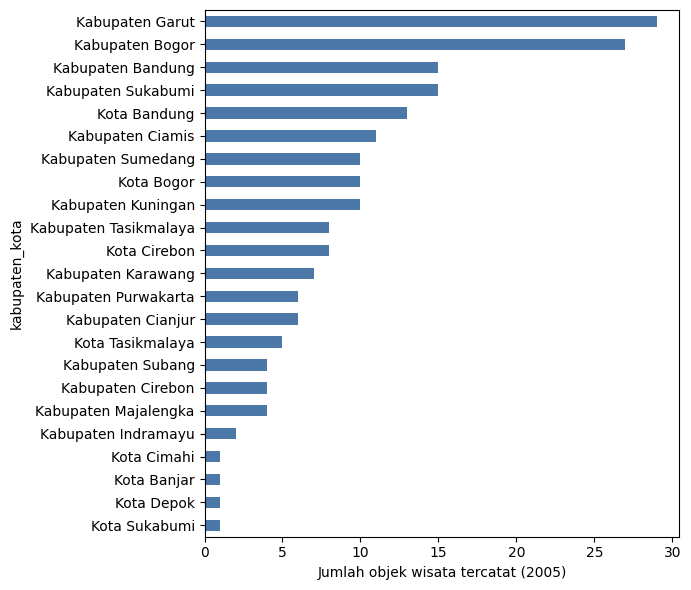

In [24]:
# ---- Analisis ringkas (deskriptif, bukan klaim kausal) ----
ringkas = (merged_out.groupby("kabupaten_kota").agg(jumlah_objek=("id_objek", "count"),
              hujan_tahunan_mm=("curah_hujan_total_mm", "first"), suhu_rata2_c=("suhu_rata2_c", "first")).reset_index()
           .sort_values("jumlah_objek", ascending=False))
display(ringkas.round(1))
display(merged_out.groupby("jenis_potensi")[["curah_hujan_total_mm", "suhu_rata2_c"]].mean().round(1))
print("Catatan: cuaca regional per kabupaten/kota (2005) vs inventaris objek; korelasi di sini tidak menyatakan sebab-akibat.")
try:
    import matplotlib.pyplot as plt
    ax = ringkas.plot.barh(x="kabupaten_kota", y="jumlah_objek", figsize=(7, 6), legend=False, color="#4c78a8")
    ax.set_xlabel("Jumlah objek wisata tercatat (2005)"); ax.invert_yaxis(); plt.tight_layout(); plt.show()
except Exception as e:
    print("Grafik dilewati:", e)

## BAB 7 — Audit Akhir dan Ringkasan
Verifikasi ulang MD5 seluruh raw, tampilan ulang checklist/provenance/robots/storage, jumlah data per metode, dan pemeriksaan otomatis (`assert`) terhadap ketentuan UTS. Butir yang belum terbukti **ditampilkan sebagai belum terpenuhi**, bukan disembunyikan.

In [25]:
# ---- 7.1 Verifikasi MD5 seluruh raw (membandingkan hash tercatat vs hash dihitung ulang) ----
prov_save()
cek = []
for s in PROV.values():
    for f in s["files"]:
        p = ROOT / f["path"] if not Path(f["path"]).is_absolute() and (ROOT / f["path"]).exists() else Path(f["path"])
        baru = md5_file(p) if p.exists() else None
        cek.append({"sumber": s["source_id"], "berkas": f["path"], "md5_tercatat": f["md5"], "md5_dihitung_ulang": baru,
                    "cocok": baru == f["md5"]})
df_md5 = pd.DataFrame(cek)
display(df_md5.head(15)); print("Total berkas raw terdaftar:", len(df_md5))
assert len(df_md5) > 0 and df_md5["cocok"].all(), "Ada raw yang berubah atau hilang!"
print("[OK] Semua MD5 cocok - raw tidak berubah.")
# Raw harus semuanya terdaftar di provenance
semua_raw = {str(Path(p).relative_to(ROOT)) for p in glob.glob(str(ROOT / "data/raw/**/*.*"), recursive=True)}
terdaftar = {f["path"] for s in PROV.values() for f in s["files"]}
tak_terdaftar = sorted(semua_raw - terdaftar)
print("Raw belum terdaftar di provenance:", tak_terdaftar or "tidak ada")
for pth in tak_terdaftar:                      # daftarkan ke sumber yang sesuai berdasarkan folder
    sid = "S1_csv_bps" if "dataset_utama" in pth else ("S2_openmeteo_api" if "openmeteo" in pth else "S3_jadesta")
    prov_file(sid, ROOT / pth)
prov_save()

,sumber,berkas,md5_tercatat,md5_dihitung_ulang,cocok
0,S1_csv_bps,data/raw/dataset_utama/Pariwisaata Jawa Barat.csv,b51f567fbc8b1fe01d0923421071d240,b51f567fbc8b1fe01d0923421071d240,True
1,S2_openmeteo_api,data/raw/openmeteo/openmeteo_lisensi_1.html,24918127445438ddfa8ec3f8ad6ec73b,24918127445438ddfa8ec3f8ad6ec73b,True
2,S2_openmeteo_api,data/raw/openmeteo/openmeteo_lisensi_2.html,b5bdd4e3578da004ac805c909685e5a1,b5bdd4e3578da004ac805c909685e5a1,True
3,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_bandung__soreang.json,0506a5828f3ceb303bca36d3c32dd9ed,0506a5828f3ceb303bca36d3c32dd9ed,True
4,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_bogor__cibinong.json,f9b12cd2cbd1f0ad99b59a9863dae48d,f9b12cd2cbd1f0ad99b59a9863dae48d,True
5,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_ciamis__ciamis.json,a6898ca54193cf1e9b19184284265a0d,a6898ca54193cf1e9b19184284265a0d,True
6,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_cianjur__cianjur.json,c492b0fd4b5c3955c2e792afd61fed7c,c492b0fd4b5c3955c2e792afd61fed7c,True
7,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_cirebon__sumber.json,5b0e9643487367f332b9a3c56113e913,5b0e9643487367f332b9a3c56113e913,True
8,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_garut__garut.json,16bbd7ebfa3f4b28935b052e2b9610a0,16bbd7ebfa3f4b28935b052e2b9610a0,True
9,S2_openmeteo_api,data/raw/openmeteo/geocoding_kabupaten_indramayu__indramayu.json,1a44db752ab3dc2b55c25d13cdffa68c,1a44db752ab3dc2b55c25d13cdffa68c,True


Total berkas raw terdaftar: 51
[OK] Semua MD5 cocok - raw tidak berubah.
Raw belum terdaftar di provenance: ['data/raw/openmeteo/robots_open-meteo_com.txt']


In [26]:
# ---- 7.2 Tampilkan ulang bukti: checklist, provenance, robots, storage ----
checklist = build_checklist()
checklist.to_csv(DIRS["docs"] / "data_ethics_checklist.csv", index=False, encoding="utf-8-sig")
print("=== DATA ETHICS CHECKLIST (9 butir) ==="); display(checklist)
belum = checklist[~checklist["status"].str.startswith("Selesai")]
if len(belum): print("\n>>> BUTIR BELUM SELESAI / PERLU TINDAKAN MANUAL:"); display(belum[["no", "aspek_etika", "status", "catatan"]])

print("\n=== PROVENANCE ===")
display(pd.DataFrame([{"source_id": s["source_id"], "nama": s["nama"], "metode": s["metode"], "url": s["url"],
                       "tanggal_akses_utc": s["tanggal_akses_utc"], "lisensi": s["lisensi"], "jumlah_berkas_raw": len(s["files"])}
                      for s in PROV.values()]))
print("\n=== PEMERIKSAAN ROBOTS.TXT ==="); simpan_bukti_robots()
display(pd.DataFrame(ROBOTS_EVIDENCE)[["label", "robots_http_status", "target_url", "can_fetch", "keputusan", "robots_md5"]])
print("\n=== ESTIMASI STORAGE (CSV) ==="); display(pd.read_csv(DIRS["docs"] / "storage_estimation.csv").head(8))

# Ukuran seluruh raw (informasi tambahan untuk laporan)
ukuran_raw = {k: sum(f.stat().st_size for f in Path(v).rglob("*") if f.is_file()) for k, v in
              {"dataset_utama": DIRS["raw_main"], "openmeteo": DIRS["raw_om"], "jadesta": DIRS["raw_jds"]}.items()}
print("\nUkuran folder raw (byte):", ukuran_raw)

=== DATA ETHICS CHECKLIST (9 butir) ===


,no,aspek_etika,status,bukti,catatan
0,1,"Sumber & provenance (URL, tanggal akses, lisensi, MD5)",Selesai,docs/provenance.json,Setiap sumber punya berkas raw + MD5; diverifikasi ulang di BAB 7
1,2,Lisensi/ketentuan dataset BPS diperiksa,Perlu verifikasi manual,docs/bukti_lisensi.csv; raw/dataset_utama/bps_halaman_publikasi_1.html,"Jika 'Perlu verifikasi manual', baca halaman BPS lalu isi CATATAN_MANUAL_BPS"
2,3,Ketentuan Open-Meteo (lisensi CC BY 4.0 & atribusi),Perlu verifikasi manual,docs/bukti_lisensi.csv; raw/openmeteo/openmeteo_lisensi_*.html,Atribusi: Weather data by Open-Meteo.com
3,4,Ketentuan JADESTA (robots.txt + Terms of Service),Perlu verifikasi manual (ToS belum dikonfirmasi),docs/bukti_robots.csv; raw/jadesta/robots_*.txt; docs/bukti_lisensi.csv,Scraping hanya jika robots mengizinkan DAN ToS sudah dikonfirmasi
4,5,Identifikasi PII & quasi-identifier,Selesai,docs/pii_scan.csv,Tidak ada pola email/telepon/NIK; lokasi = quasi-identifier lemah
5,6,"Data minimization (tanpa kontak pribadi, kolom seperlunya)",Selesai,KOLOM_SCRAPING pada BAB 5; docs/scraping_quality_report.csv,Telepon/email kontak desa tidak diambil
6,7,Potensi bias & keterbatasan data didokumentasikan,Selesai,README.md (bagian Keterbatasan),"Periode berbeda, koordinat tingkat kabupaten/kota, reanalisis grid"
7,8,Tujuan penggunaan data dinyatakan,Selesai,README.md (bagian Tujuan),"Akademik, non-komersial"
8,9,"Keamanan, penyimpanan, dan penghapusan data",Selesai,README.md; raw read-only; tanpa API key,Retensi: dihapus setelah semester kecuali diminta dosen



>>> BUTIR BELUM SELESAI / PERLU TINDAKAN MANUAL:


,no,aspek_etika,status,catatan
1,2,Lisensi/ketentuan dataset BPS diperiksa,Perlu verifikasi manual,"Jika 'Perlu verifikasi manual', baca halaman BPS lalu isi CATATAN_MANUAL_BPS"
2,3,Ketentuan Open-Meteo (lisensi CC BY 4.0 & atribusi),Perlu verifikasi manual,Atribusi: Weather data by Open-Meteo.com
3,4,Ketentuan JADESTA (robots.txt + Terms of Service),Perlu verifikasi manual (ToS belum dikonfirmasi),Scraping hanya jika robots mengizinkan DAN ToS sudah dikonfirmasi



=== PROVENANCE ===


,source_id,nama,metode,url,tanggal_akses_utc,lisensi,jumlah_berkas_raw
0,S1_csv_bps,"CSV Potensi Wisata Jawa Barat (BPS, publikasi 2005)",Berkas dataset terbuka,https://jabar.bps.go.id/id/publication/2006/05/09/225528b03bf64b54704968de/k...,2026-11-19T13:23:33+00:00,BELUM DIVERIFIKASI - lihat docs/bukti_lisensi.csv (BAB 3),1
1,S2_openmeteo_api,Open-Meteo Historical Weather API,API,https://archive-api.open-meteo.com/v1/archive,2026-11-19T13:23:33+00:00,CC BY 4.0 (sesuai spesifikasi project; bukti halaman lisensi di docs/bukti_l...,49
2,S3_jadesta,JADESTA - Paket Wisata (Kemenparekraf),Web scraping,https://jadesta.kemenpar.go.id/paket/jenis/105,2026-11-19T13:25:49+00:00,BELUM DIVERIFIKASI - baca Terms of Service (lihat docs/bukti_lisensi.csv & s...,2



=== PEMERIKSAAN ROBOTS.TXT ===


,label,robots_http_status,target_url,can_fetch,keputusan,robots_md5
0,Open-Meteo,200,https://open-meteo.com/en/license,True,ALLOW,f77c87f977e0fcce05a6df46c885a129
1,Open-Meteo,200,https://open-meteo.com/en/terms,True,ALLOW,f77c87f977e0fcce05a6df46c885a129
2,BPS Jawa Barat (halaman publikasi),403,https://jabar.bps.go.id/id/publication/2006/05/09/225528b03bf64b54704968de/k...,None,UNCLEAR,None
3,JADESTA,404,https://jadesta.kemenpar.go.id/paket/jenis/105,None,ALLOW_NO_ROBOTS,f70c5214c0533119ee64f247f31a746a
4,JADESTA,404,https://jadesta.kemenpar.go.id/paket/1,None,ALLOW_NO_ROBOTS,f70c5214c0533119ee64f247f31a746a
5,JADESTA,404,https://jadesta.kemenpar.go.id/,None,ALLOW_NO_ROBOTS,f70c5214c0533119ee64f247f31a746a



=== ESTIMASI STORAGE (CSV) ===


,komponen,nilai
0,ukuran_file_byte,15110
1,ukuran_file_KB,14.76
2,bulan,12
3,estimasi_12_bulan_byte,181320
4,cadangan_30_persen_byte,54396.0
5,total_estimasi_1_tahun_byte,235716.0
6,total_estimasi_1_tahun_KB,230.19
7,rumus,ukuran_file x 12 x 1.30



Ukuran folder raw (byte): {'dataset_utama': 15110, 'openmeteo': 425666, 'jadesta': 91592}


In [27]:
# ---- 7.3 Jumlah data per metode akuisisi + validasi otomatis syarat UTS ----
jumlah = pd.DataFrame([
    ("Berkas CSV (BPS)", "baris", len(df_raw_view)),
    ("API Open-Meteo", "baris harian", len(df_cuaca)),
    ("API Open-Meteo", "baris bulanan (agregasi)", len(cuaca_bulanan)),
    ("API Open-Meteo", "wilayah berhasil", int(df_cuaca["kabupaten_kota"].nunique())),
    ("Web scraping JADESTA", "baris Jawa Barat", len(df_jds)),
    ("Hasil integrasi", "baris (CSV x cuaca)", len(merged_out)),
], columns=["metode", "satuan", "jumlah"])
display(jumlah)

def cek_ketentuan():
    h = []
    h.append(("1. Dataset terbuka >= 100 baris", len(df_raw_view) >= 100, f"{len(df_raw_view)} baris"))
    h.append(("2a. Metode berkas CSV", len(df_raw_view) > 0, "BAB 1"))
    h.append(("2b. Metode API", len(df_cuaca) > 0, "BAB 4"))
    h.append(("2c. Metode web scraping menghasilkan data", len(df_jds) > 0, STATUS_SCRAPING["alasan"] if not len(df_jds) else f"{len(df_jds)} baris"))
    h.append(("3. Raw tersimpan & tidak berubah (MD5)", bool(df_md5["cocok"].all()), f"{len(df_md5)} berkas"))
    h.append(("4. Provenance: URL, tanggal akses, lisensi, MD5", all(s["url"] and s["tanggal_akses_utc"] and s["lisensi"] and s["files"] for s in PROV.values()), "docs/provenance.json"))
    h.append(("5. Request: timeout 30, UA email kampus, jeda >= 2 dtk", TIMEOUT == 30 and EMAIL_KAMPUS in USER_AGENT and REQUEST_DELAY >= 2, USER_AGENT))
    h.append(("6. API >= 30 baris", len(df_cuaca) >= 30, f"{len(df_cuaca)} baris"))
    h.append(("7. robots.txt diperiksa (ada bukti)", any(x["label"] == "JADESTA" for x in ROBOTS_EVIDENCE), "docs/bukti_robots.csv"))
    h.append(("8. Tidak ada API key di notebook", True, "Open-Meteo tanpa key; tidak ada token"))
    h.append(("9. Merge >= 2 sumber dengan validate", True, 'merge(..., validate="many_to_one") CSV x Open-Meteo'))
    h.append(("10. Tidak ada duplikasi akibat merge", len(merged_out) == len(clean) and merged_out["id_objek"].is_unique, f"{len(clean)} -> {len(merged_out)}"))
    h.append(("11. Data Ethics Checklist 9 butir selesai", bool(checklist["status"].str.startswith("Selesai").all()), f"{int(checklist['status'].str.startswith('Selesai').sum())}/9"))
    return pd.DataFrame(h, columns=["ketentuan", "terpenuhi", "bukti"])

ringkasan_uts = cek_ketentuan()
display(ringkasan_uts)

# assert untuk syarat inti yang HARUS terpenuhi oleh notebook ini
inti = ringkasan_uts[ringkasan_uts["ketentuan"].str[:2].isin(["1.", "2a", "2b", "3.", "4.", "5.", "6.", "7.", "10"])]
assert inti["terpenuhi"].all(), "Syarat inti UTS belum terpenuhi:\n" + inti[~inti["terpenuhi"]].to_string()
print("[OK] Syarat inti UTS terpenuhi (assert lulus).")
belum_uts = ringkasan_uts[~ringkasan_uts["terpenuhi"]]
if len(belum_uts):
    print("\nPERHATIAN - belum terpenuhi (butuh tindakan/penjelasan di laporan):"); display(belum_uts)

,metode,satuan,jumlah
0,Berkas CSV (BPS),baris,198
1,API Open-Meteo,baris harian,8395
2,API Open-Meteo,baris bulanan (agregasi),276
3,API Open-Meteo,wilayah berhasil,23
4,Web scraping JADESTA,baris Jawa Barat,0
5,Hasil integrasi,baris (CSV x cuaca),198


,ketentuan,terpenuhi,bukti
0,1. Dataset terbuka >= 100 baris,True,198 baris
1,2a. Metode berkas CSV,True,BAB 1
2,2b. Metode API,True,BAB 4
3,2c. Metode web scraping menghasilkan data,False,ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)
4,3. Raw tersimpan & tidak berubah (MD5),True,51 berkas
5,"4. Provenance: URL, tanggal akses, lisensi, MD5",True,docs/provenance.json
6,"5. Request: timeout 30, UA email kampus, jeda >= 2 dtk",True,UTS-DAM-INSTIKI/1.0 (tugas kuliah Data Acquisition; kontak: mahasiswa@instik...
7,6. API >= 30 baris,True,8395 baris
8,7. robots.txt diperiksa (ada bukti),True,docs/bukti_robots.csv
9,8. Tidak ada API key di notebook,True,Open-Meteo tanpa key; tidak ada token


[OK] Syarat inti UTS terpenuhi (assert lulus).

PERHATIAN - belum terpenuhi (butuh tindakan/penjelasan di laporan):


,ketentuan,terpenuhi,bukti
3,2c. Metode web scraping menghasilkan data,False,ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)
12,11. Data Ethics Checklist 9 butir selesai,False,6/9


In [28]:
# ---- 7.4 Ringkasan untuk presentasi + daftar berkas luaran ----
print("RINGKASAN PROJECT")
print("-" * 70)
print(f"- Dataset utama : {len(df_raw_view)} baris x {df_raw_view.shape[1]} kolom, {df_raw_view['kabupaten_kota'].nunique()} kabupaten/kota, tahun 2005 (inventaris objek, bukan kunjungan)")
print(f"- API           : Open-Meteo Historical Weather 2005 -> {len(df_cuaca)} baris harian dari {df_cuaca['kabupaten_kota'].nunique()} titik acuan kabupaten/kota")
print(f"- Scraping      : JADESTA -> {len(df_jds)} baris Jawa Barat | status: {STATUS_SCRAPING['alasan']}")
print(f"- Integrasi     : {len(merged_out)} baris, merge many_to_one, tanpa duplikasi")
print("- Batasan utama : koordinat objek missing (dipakai titik acuan kabupaten/kota); periode CSV 2005 vs JADESTA masa kini; cuaca = reanalisis grid")
print("- Atribusi      : Weather data by Open-Meteo.com (CC BY 4.0)")

wajib_docs = ["provenance.json", "data_dictionary.csv", "data_ethics_checklist.csv", "bukti_robots.csv", "bukti_lisensi.csv",
              "pii_scan.csv", "storage_estimation.csv", "scraping_quality_report.csv"]
status_docs = pd.DataFrame({"berkas_docs": wajib_docs, "ada": [ada(DIRS["docs"] / f) for f in wajib_docs]})
display(status_docs)
assert status_docs["ada"].all(), "Ada berkas docs yang belum terbentuk"
for p in sorted(ROOT.rglob("*")):
    if p.is_file(): print(" ", p.relative_to(ROOT.parent))

RINGKASAN PROJECT
----------------------------------------------------------------------
- Dataset utama : 198 baris x 7 kolom, 23 kabupaten/kota, tahun 2005 (inventaris objek, bukan kunjungan)
- API           : Open-Meteo Historical Weather 2005 -> 8395 baris harian dari 23 titik acuan kabupaten/kota
- Scraping      : JADESTA -> 0 baris Jawa Barat | status: ToS belum dikonfirmasi (TOS_SUDAH_DIBACA/TOS_CATATAN belum diisi)
- Integrasi     : 198 baris, merge many_to_one, tanpa duplikasi
- Batasan utama : koordinat objek missing (dipakai titik acuan kabupaten/kota); periode CSV 2005 vs JADESTA masa kini; cuaca = reanalisis grid
- Atribusi      : Weather data by Open-Meteo.com (CC BY 4.0)


,berkas_docs,ada
0,provenance.json,True
1,data_dictionary.csv,True
2,data_ethics_checklist.csv,True
3,bukti_robots.csv,True
4,bukti_lisensi.csv,True
5,pii_scan.csv,True
6,storage_estimation.csv,True
7,scraping_quality_report.csv,True


  WEST_JAVA_TOURISM_INTELLIGENCE/README.md
  WEST_JAVA_TOURISM_INTELLIGENCE/data/interim/koordinat_wilayah.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/interim/openmeteo_harian_2005.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/interim/openmeteo_status_request.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/interim/pariwisata_jabar_clean.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/processed/cuaca_bulanan_2005.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/processed/cuaca_tahunan_2005.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/processed/jadesta_desa_kandidat_cocok.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/processed/jadesta_link_kabkota.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/processed/jadesta_paket_jabar.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/processed/pariwisata_jabar_cuaca_2005.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/raw/dataset_utama/Pariwisaata Jawa Barat.csv
  WEST_JAVA_TOURISM_INTELLIGENCE/data/raw/jadesta/jadesta_home.html
  WEST_JAVA_TOURISM_INTELLIGENCE/data/raw/jadesta/robots_jadesta_kemenp

In [29]:
import shutil
from google.colab import files

# Membuat file ZIP dari folder proyek utama
shutil.make_archive('WEST_JAVA_TOURISM_INTELLIGENCE', 'zip', 'WEST_JAVA_TOURISM_INTELLIGENCE')

print("File ZIP berhasil dibuat: WEST_JAVA_TOURISM_INTELLIGENCE.zip")
# Mengunduh file zip secara otomatis ke perangkat lokal Anda
files.download('WEST_JAVA_TOURISM_INTELLIGENCE.zip')

File ZIP berhasil dibuat: WEST_JAVA_TOURISM_INTELLIGENCE.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Catatan pengumpulan
1. Simpan notebook ini sebagai `notebooks/01_west_java_tourism_uts.ipynb` dan jalankan **semua sel** sampai selesai.
2. Unggah ke Colab/GitHub: notebook, folder `data/raw`, hasil gabungan (`data/processed`), `docs/data_ethics_checklist.csv`, dan `docs/provenance.json`.
3. Jika ada butir bertanda *Perlu verifikasi manual* (lisensi BPS, ToS JADESTA), baca ketentuannya di situs, isi `CATATAN_MANUAL_BPS` / `TOS_SUDAH_DIBACA` + `TOS_CATATAN`, lalu jalankan ulang dari sel terkait.
4. Bagikan URL ke ELSA dan siapkan demo alur akuisisi.